# E-commerce Sales & Customer Behaviour Analysis
### Olist Brazilian E-commerce — 99,441 orders, R$ 15.4M revenue (2016-09 → 2018-08)

**Business question**

> *Ek online store ke sales, customers aur products ka analysis karke business ko batana ki revenue kaise badha sakte hain aur kaun se customers sabse valuable hain.*
>
> In English: **how do we grow revenue, and which customers are actually valuable?**

**Dataset** — [Olist Brazilian E-commerce Public Dataset](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) (Kaggle), 9 relational tables:
`orders`, `order_items`, `order_payments`, `order_reviews`, `customers`, `products`, `sellers`, `geolocation`, `product_category_name_translation`.

**How this notebook is organised** (follows the project plan)

| Step | What | Cell section |
|---|---|---|
| 1 | Load & understand the 9 tables | §1 |
| 2 | Clean, fix dtypes, filter cancellations, build master table | §2 |
| 3 | SQL analysis (monthly trend, categories, states, delivery, window functions) | §3 |
| 4 | EDA (trend, seasonality, payments, reviews, category AOV) | §4 |
| 5 | Advanced: RFM, cohort retention, Pareto | §5 |
| 6 | Dashboard (4 pages, interactive HTML) | §6 |
| 7 | Insights & recommendations | §7 |

**Reproducibility** — the importable pipeline lives in `src/`. This notebook calls it so the numbers
here are exactly the numbers in the SQL file, the dashboard and the report.

```
python -m src.etl             # raw CSVs -> cleaned tables + master + SQLite
python -m src.sql_analysis    # runs sql/02_analysis_queries.sql
python -m src.analysis        # EDA figures + RFM/cohort/Pareto + metrics.json
python -m dashboard.build_dashboard
```

---
## 0. Setup

In [1]:
import sys, json, sqlite3
from pathlib import Path

# make `src` importable when the notebook is opened from notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown

from src.config import DATA_RAW, DATA_PROCESSED, FIGURES_DIR, DB_PATH, PALETTE
from src.viz import apply_style

apply_style()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

def show(fig_name, width=980):
    # display a figure that src.analysis saved to reports/figures/
    display(Image(filename=str(FIGURES_DIR / f"{fig_name}.png"), width=width))

print("project root:", ROOT)
print("raw data    :", DATA_RAW)
print("processed   :", DATA_PROCESSED)

project root: C:\Users\shiva\Desktop\college project\E-commerce Sales & Customer Behavior Analysis
raw data    : C:\Users\shiva\Desktop\college project\E-commerce Sales & Customer Behavior Analysis\data\raw
processed   : C:\Users\shiva\Desktop\college project\E-commerce Sales & Customer Behavior Analysis\data\processed


---
## 1. Step 1 — Load the data and understand the relationships

The nine tables form a small star schema around **orders**. Keys that matter:

```
customers (customer_id = one per ORDER, customer_unique_id = one per PERSON)
     │
orders (order_id, customer_id, status, 5 timestamps)
     │
     ├──< order_items (order_id, order_item_id, product_id, seller_id, price, freight)
     │         ├── products (product_id, category)
     │         └── sellers  (seller_id)
     ├──< order_payments (order_id, payment_sequential, type, installments, value)
     └──< order_reviews  (order_id, review_id, score)

geolocation (zip prefix -> lat/lng)   product_category_name_translation (pt -> en)
```

Two traps that bite every Olist analysis:

1. **`customer_id` is regenerated for every order** — it is an order-level key, *not* a person.
   Repeat behaviour must be measured on `customer_unique_id` (99,441 vs 96,096 rows).
2. **`order_items` is item-grain** — an order can have many rows. Summing `payment_value`
   on that grain multiplies revenue. All order KPIs below use one row per order.

In [2]:
from src.etl import load_raw, audit_tables

raw = load_raw()

  loaded orders                 99,441 rows x 8 cols
  loaded customers              99,441 rows x 5 cols


  loaded order_items           112,650 rows x 7 cols
  loaded payments              103,886 rows x 5 cols


  loaded reviews                99,224 rows x 7 cols
  loaded products               32,951 rows x 9 cols
  loaded sellers                 3,095 rows x 4 cols


  loaded geolocation          1,000,163 rows x 5 cols
  loaded category_translation       71 rows x 2 cols


In [3]:
audit = audit_tables(raw)
audit

,table,rows,columns,missing_cells_%,duplicate_rows,unique_order_id,unique_customer_id,unique_product_id,unique_seller_id,unique_geolocation_zip_code_prefix,unique_product_category_name
0,orders,99441,8,0.62,0,"99,441.00",NaN,NaN,NaN,NaN,NaN
1,customers,99441,5,0.00,0,NaN,"99,441.00",NaN,NaN,NaN,NaN
2,order_items,112650,7,0.00,0,"98,666.00",NaN,NaN,NaN,NaN,NaN
3,payments,103886,5,0.00,0,"99,440.00",NaN,NaN,NaN,NaN,NaN
4,reviews,99224,7,21.01,0,"98,673.00",NaN,NaN,NaN,NaN,NaN
5,products,32951,9,0.83,0,NaN,NaN,"32,951.00",NaN,NaN,NaN
6,sellers,3095,4,0.00,0,NaN,NaN,NaN,"3,095.00",NaN,NaN
7,geolocation,1000163,5,0.00,261831,NaN,NaN,NaN,NaN,"19,015.00",NaN
8,category_translation,71,2,0.00,0,NaN,NaN,NaN,NaN,NaN,71.00


**Reading the audit**

| Observation | Consequence for the analysis |
|---|---|
| `geolocation` has 1,000,163 rows for 19,015 zips and **261,831 duplicates** | join on aggregated zip-prefix centroids, never row-to-row |
| `reviews` has 21% empty cells (most comment fields are blank) | we only use `review_score`, and de-duplicate orders with 2+ reviews |
| `products` has 610 rows with no category | label them `Unknown` instead of dropping R$ revenue |
| `orders` has **0.62%** empty cells (delivery timestamps of undelivered orders) | keep those rows, but delivery metrics must ignore NULLs |
| `order_items` covers 98,666 of 99,441 orders | ~775 orders have no item row (cancelled / unavailable) |

In [4]:
# relationship sanity checks -------------------------------------------------
checks = {
    "orders with a customer": raw["orders"]["customer_id"].isin(raw["customers"]["customer_id"]).mean(),
    "order_items orders that exist in orders":
        raw["order_items"]["order_id"].isin(raw["orders"]["order_id"]).mean(),
    "order_items products that exist in products":
        raw["order_items"]["product_id"].isin(raw["products"]["product_id"]).mean(),
    "order_items sellers that exist in sellers":
        raw["order_items"]["seller_id"].isin(raw["sellers"]["seller_id"]).mean(),
    "payments orders that exist in orders":
        raw["payments"]["order_id"].isin(raw["orders"]["order_id"]).mean(),
    "customers with a matching geolocation zip":
        raw["customers"]["customer_zip_code_prefix"].isin(
            raw["geolocation"]["geolocation_zip_code_prefix"]).mean(),
}
pd.Series({k: f"{v*100:.2f}%" for k, v in checks.items()}).to_frame("referential integrity")

,referential integrity
orders with a customer,100.00%
order_items orders that exist in orders,100.00%
order_items products that exist in products,100.00%
order_items sellers that exist in sellers,100.00%
payments orders that exist in orders,100.00%
customers with a matching geolocation zip,99.72%


In [5]:
# how many items per order / payments per order? (decides the aggregation strategy)
print("items per order  :", raw["order_items"].groupby("order_id").size().describe()[["mean", "max"]].to_dict())
print("payments per order:", raw["payments"].groupby("order_id").size().describe()[["mean", "max"]].to_dict())
print("orders with 2+ reviews:", raw["reviews"]["order_id"].duplicated().sum())

raw["orders"]["order_status"].value_counts().to_frame("orders")

items per order  : {'mean': 1.1417306873695092, 'max': 21.0}
payments per order: {'mean': 1.0447103781174578, 'max': 29.0}
orders with 2+ reviews: 551


,orders
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


---
## 2. Step 2 — Cleaning

Rules applied (all implemented in `src/etl.py`):

| Problem | Fix |
|---|---|
| 5 order timestamps + 1 shipping deadline + 2 review dates are strings | `pd.to_datetime(..., errors="coerce")` |
| `order_items.price` / `freight_value` | numeric, drop non-positive rows |
| `customer_id` repeated per order | keep it, add `customer_unique_id` to every row |
| `payments` has 103,886 rows for 99,441 orders (vouchers + split payments) | collapse to 1 row/order: total value, max installments, dominant type |
| `reviews` has 551 orders with more than one review | keep the latest `review_answer_timestamp` |
| 610 products with no category | fill `Unknown`, translate PT → EN |
| `geolocation` 1M rows | aggregate to zip-prefix centroid (median lat/lng, modal city) |
| `canceled` + `unavailable` orders (1,234) | flag `is_cancelled`, exclude from the revenue universe |
| impossible timestamps (delivery before purchase) | set to NaN |

In [6]:
from src.etl import (
    clean_customers, clean_orders, clean_order_items, clean_payments,
    clean_reviews, clean_products, clean_sellers, build_geo,
)

orders   = clean_orders(raw["orders"])
items    = clean_order_items(raw["order_items"])
customers = clean_customers(raw["customers"])
products = clean_products(raw["products"], raw["category_translation"])
payments = clean_payments(raw["payments"])
reviews  = clean_reviews(raw["reviews"])
sellers  = clean_sellers(raw["sellers"])
geo      = build_geo(raw["geolocation"])

print(f"orders      {len(orders):>8,}  |  delivered {orders.is_revenue_order.sum():>7,}"
      f"  |  cancelled/unavailable {orders.is_cancelled.sum():>5,}")
print(f"payments    {len(raw['payments']):>8,} rows -> {len(payments):,} orders")
print(f"reviews     {len(raw['reviews']):>8,} rows -> {len(reviews):,} orders")
print(f"products    {len(products):>8,}  |  distinct categories {products.category.nunique()}")
print(f"geolocation {len(raw['geolocation']):>8,} rows -> {len(geo):,} zip centroids")

orders        99,441  |  delivered  96,478  |  cancelled/unavailable 1,234
payments     103,886 rows -> 99,440 orders
reviews       99,224 rows -> 98,673 orders
products      32,951  |  distinct categories 74
geolocation 1,000,163 rows -> 19,015 zip centroids


In [7]:
# what the datetime fix bought us: delivery performance is now computable
orders[["order_id", "order_purchase_timestamp", "order_delivered_customer_date",
        "delivery_days", "estimated_days", "delay_days", "is_late"]].dropna().head()

,order_id,order_purchase_timestamp,order_delivered_customer_date,delivery_days,estimated_days,delay_days,is_late
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-02 10:56:33,2017-10-10 21:25:13,8.44,15.54,-7.11,0
1,53cdb2fc8bc7dce0b6741e2150273451,2018-07-24 20:41:37,2018-08-07 15:27:45,13.78,19.14,-5.36,0
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08-08 08:38:49,2018-08-17 18:06:29,9.39,26.64,-17.25,0
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-11-18 19:28:06,2017-12-02 00:28:42,13.21,26.19,-12.98,0
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-13 21:18:39,2018-02-16 18:17:02,2.87,12.11,-9.24,0


In [8]:
from src.etl import build_master

tables = {
    "_orders_clean": orders, "_items_clean": items, "_customers_clean": customers,
    "_products_clean": products, "_sellers_clean": sellers, "_payments_clean": payments,
    "_reviews_clean": reviews, "_geo": geo,
}
master = build_master(tables)
print(f"master: {len(master):,} item rows | {master.order_id.nunique():,} orders | "
      f"{master.customer_unique_id.nunique():,} customers")
master.head(3)

master: 112,650 item rows | 98,666 orders | 95,420 customers


,order_id,order_item_id,customer_id,customer_unique_id,order_status,order_purchase_timestamp,purchase_date,purchase_month,purchase_month_key,purchase_year,purchase_dow,purchase_hour,is_weekend,order_delivered_customer_date,order_estimated_delivery_date,delivery_days,estimated_days,delay_days,is_late,is_cancelled,is_revenue_order,approval_hours,carrier_days,last_mile_days,product_id,category,product_category_name,seller_id,seller_state,customer_state,customer_city,customer_zip_code_prefix,customer_lat,customer_lng,price,freight_value,item_total,freight_share,payment_value,payment_type,payment_installments,n_payment_records,review_score,has_comment,product_weight_g,product_volume_cm3,product_photos_qty
0,00010242fe8c5a6d1ba2dd792cb16214,1,3ce436f183e68e07877b285a838db11a,871766c5855e863f6eccc05f988b23cb,delivered,2017-09-13 08:59:02,2017-09-13,2017-09-01,2017-09,2017,Wednesday,8,False,2017-09-20 23:43:48,2017-09-29,7.61,15.63,-8.01,0,False,True,0.78,6.37,1.21,4244733e06e7ecb4970a6e2683c13e61,Cool Stuff,cool_stuff,48436dade18ac8b2bce089ec2a041202,SP,RJ,Campos Dos Goytacazes,28013,-21.76,-41.31,58.90,13.29,72.19,0.18,72.19,credit_card,2.00,1.00,5.00,1.00,650.00,"3,528.00",4.00
1,00018f77f2f0320c557190d7a144bdd3,1,f6dd3ec061db4e3987629fe6b26e5cce,eb28e67c4c0b83846050ddfb8a35d051,delivered,2017-04-26 10:53:06,2017-04-26,2017-04-01,2017-04,2017,Wednesday,10,False,2017-05-12 16:04:24,2017-05-15,16.22,18.55,-2.33,0,False,True,0.20,8.15,8.06,e5f2d52b802189ee658865ca93d83a8f,Pet Shop,pet_shop,dd7ddc04e1b6c2c614352b383efe2d36,SP,SP,Santa Fe Do Sul,15775,-20.21,-50.93,239.90,19.93,259.83,0.08,259.83,credit_card,3.00,1.00,4.00,0.00,"30,000.00","60,000.00",2.00
2,000229ec398224ef6ca0657da4fc703e,1,6489ae5e4333f3693df5ad4372dab6d3,3818d81c6709e39d06b2738a8d3a2474,delivered,2018-01-14 14:33:31,2018-01-14,2018-01-01,2018-01,2018,Sunday,14,True,2018-01-22 13:19:16,2018-02-05,7.95,21.39,-13.44,0,False,True,0.25,1.91,6.03,c777355d18b72b67abbeef9df44fd0fd,Furniture Decor,moveis_decoracao,5b51032eddd242adc84c38acab88f23d,MG,MG,Para De Minas,35661,-19.87,-44.59,199.00,17.87,216.87,0.08,216.87,credit_card,5.00,1.00,5.00,1.00,"3,050.00","14,157.00",2.00


In [9]:
# revenue reconciliation + sanity checks before we trust any number
delivered = master[master.is_revenue_order]
recon = pd.Series({
    "item-grain revenue (price + freight)": delivered.item_total.sum(),
    "payment revenue (money collected)": delivered.drop_duplicates("order_id").payment_value.sum(),
    "difference": delivered.item_total.sum() - delivered.drop_duplicates("order_id").payment_value.sum(),
    "cancelled/unavailable orders excluded": int(orders.is_cancelled.sum()),
    "share of orders cancelled (%)": orders.is_cancelled.mean() * 100,
})
recon.to_frame("value")

,value
item-grain revenue (price + freight),"15,419,773.75"
payment revenue (money collected),"15,422,461.77"
difference,"-2,688.02"
cancelled/unavailable orders excluded,"1,234.00"
share of orders cancelled (%),1.24


Both revenue definitions land within **0.02%** of each other — the joins did not multiply rows
(the classic item-grain fan-out bug). We use:

* **order revenue = `payment_value`** → KPIs, AOV, RFM monetary
* **item revenue = `price + freight_value`** → category / product / state / seller cuts

---
## 3. Step 3 — SQL analysis

The cleaned tables are loaded into `data/processed/olist.db` (SQLite) so the SQL file runs as-is.
`sql/02_analysis_queries.sql` contains 13 annotated queries — the same file works on MySQL 8 / PostgreSQL.

We execute them here and print the results.

In [10]:
from src.sql_analysis import run_all as run_sql

q = run_sql(verbose=False)
print(f"{len(q)} queries executed against {DB_PATH.name}\n")
print(list(q))


13/13 queries executed -> C:\Users\shiva\Desktop\college project\E-commerce Sales & Customer Behavior Analysis\reports\sql_results
13 queries executed against olist.db

['q1_monthly_revenue_trend', 'q2_top10_categories', 'q3_state_performance', 'q4_delivery_vs_promise', 'q4b_delivery_overall', 'q5_category_rank_by_state', 'q6_payment_methods', 'q7_reviews_vs_delay', 'q8_product_pareto', 'q9_seller_leaderboard', 'q10_rfm_segments', 'q11_cohort_retention', 'q12_repeat_purchase']


In [11]:
# Q1 — monthly revenue & orders, with MoM growth and running total (window functions)
q["q1_monthly_revenue_trend"].tail(12)

,month,orders,item_revenue,payment_revenue,aov,running_total_revenue,prev_month_revenue,mom_growth_pct,revenue_3m_ma
11,2017-09,4150,"701,077.49","701,169.99",168.93,"4,220,629.48","645,832.36",8.55,"637,736.31"
12,2017-10,4478,"751,117.01","751,140.27",167.73,"4,971,746.49","701,077.49",7.14,"699,342.29"
13,2017-11,7289,"1,153,364.20","1,153,528.05",158.23,"6,125,110.69","751,117.01",53.55,"868,519.57"
14,2017-12,5513,"843,078.29","843,199.17",152.93,"6,968,188.98","1,153,364.20",-26.90,"915,853.17"
15,2018-01,7069,"1,077,887.46","1,078,606.86",152.48,"8,046,076.44","843,078.29",27.85,"1,024,776.65"
16,2018-02,6555,"966,168.41","966,510.88",147.39,"9,012,244.85","1,077,887.46",-10.36,"962,378.05"
17,2018-03,7003,"1,120,598.24","1,120,678.00",160.02,"10,132,843.09","966,168.41",15.98,"1,054,884.70"
18,2018-04,6798,"1,132,878.93","1,132,933.95",166.65,"11,265,722.02","1,120,598.24",1.10,"1,073,215.19"
19,2018-05,6749,"1,128,774.52","1,128,836.69",167.25,"12,394,496.54","1,132,878.93",-0.36,"1,127,417.23"
20,2018-06,6099,"1,011,978.29","1,012,090.68",165.93,"13,406,474.83","1,128,774.52",-10.35,"1,091,210.58"


In [12]:
# Q2 — top 10 categories by revenue, share and cumulative (Pareto) share
q["q2_top10_categories"]

,category,orders,units,revenue,revenue_share_pct,cumulative_share_pct,revenue_rank
0,Health Beauty,8647,10849,"1,412,089.53",9.16,9.16,1
1,Watches Gifts,5495,6459,"1,264,333.12",8.20,17.36,2
2,Bed Bath Table,9272,13485,"1,225,209.26",7.95,25.30,3
3,Sports Leisure,7530,9698,"1,118,256.91",7.25,32.55,4
4,Computers Accessories,6530,9650,"1,032,723.77",6.70,39.25,5
5,Furniture Decor,6307,11302,"880,329.92",5.71,44.96,6
6,Housewares,5743,8831,"758,392.25",4.92,49.88,7
7,Cool Stuff,3559,3993,"691,680.89",4.49,54.37,8
8,Auto,3810,4772,"669,454.75",4.34,58.71,9
9,Garden Tools,3448,5773,"567,145.68",3.68,62.38,10


In [13]:
# Q3 — state-wise sales: where the money is vs where the customers are
q["q3_state_performance"].head(10)

,state,orders,customers,revenue,revenue_per_order,revenue_share_pct,freight_pct_of_revenue,avg_delivery_days,pct_late,revenue_rank
0,SP,40501,39156,"5,769,703.15",142.46,37.42,12.17,8.70,5.77,1
1,RJ,12350,11917,"2,055,401.57",166.43,13.33,14.39,15.10,12.97,2
2,MG,11354,11001,"1,818,891.67",160.20,11.80,14.65,12.00,5.44,3
3,RS,5345,5168,"861,472.79",161.17,5.59,15.39,15.20,6.88,4
4,PR,4923,4769,"781,708.80",158.79,5.07,14.79,11.90,4.78,5
5,SC,3546,3449,"595,127.78",167.83,3.86,14.81,15.00,9.62,6
6,BA,3256,3158,"591,137.81",181.55,3.83,16.50,19.20,13.68,7
7,DF,2080,2019,"346,123.35",166.41,2.24,14.34,13.00,7.43,8
8,GO,1957,1895,"334,212.35",170.78,2.17,15.37,15.40,7.86,9
9,ES,1995,1928,"317,657.93",159.23,2.06,15.43,15.60,12.22,10


In [14]:
# Q4 — delivery time vs the promise, by state (reliability question)
q["q4_delivery_vs_promise"].head(10)

,state,delivered_orders,avg_promised_days,avg_actual_days,avg_delay_days,pct_on_or_before_promise,worst_delay_days,pct_late,slowest_rank
0,AM,145,45.30,26.40,-18.90,95.86,104.70,4.14,1
1,AL,397,32.60,24.50,-8.00,76.07,50.70,23.93,2
2,PA,946,37.20,23.80,-13.40,87.63,165.60,12.37,3
3,MA,717,30.50,21.60,-8.90,80.33,135.00,19.67,4
4,SE,335,30.80,21.50,-9.30,84.78,166.60,15.22,5
5,CE,1279,31.40,21.30,-10.10,84.68,132.60,15.32,6
6,PB,517,33.00,20.40,-12.60,88.97,65.80,11.03,7
7,PI,476,30.10,19.50,-10.60,84.03,161.60,15.97,8
8,RO,243,38.80,19.40,-19.40,97.12,15.50,2.88,9
9,BA,3256,29.40,19.30,-10.10,85.96,138.60,14.04,10


In [15]:
# Q5 — window function: RANK() the top-3 categories inside every state
q["q5_category_rank_by_state"].head(12)

,state,rnk,category,orders,revenue,share_in_state_pct
0,AC,1,Sports Leisure,9,"2,071.54",10.58
1,AC,2,Furniture Decor,7,"1,746.70",8.92
2,AC,3,Health Beauty,6,"1,655.00",8.45
3,AL,1,Health Beauty,62,"14,741.33",15.65
4,AL,2,Watches Gifts,34,"12,650.16",13.43
5,AL,3,Computers Accessories,32,"8,849.85",9.40
6,AM,1,Health Beauty,15,"3,368.68",12.21
7,AM,2,Computers Accessories,10,"2,424.21",8.79
8,AM,3,Garden Tools,5,"2,267.80",8.22
9,AP,1,Computers Accessories,6,"2,322.19",14.39


In [16]:
# Q8 + Q12 — concentration of revenue in products, and repeat-purchase reality
display(q["q8_product_pareto"])
display(q["q12_repeat_purchase"])

,total_products,products_for_80pct_revenue,pct_products_for_80pct_revenue
0,32216,9055,28.11


,orders_per_customer,customers,customer_share_pct,revenue,revenue_share_pct,avg_ltv
0,1,90557,97.00,"14,558,104.56",94.40,160.76
1,2,2573,2.76,"748,808.38",4.86,291.03
2,3,181,0.19,"78,445.86",0.51,433.40
3,4,28,0.03,"22,086.28",0.14,788.80
4,5,9,0.01,"6,607.63",0.04,734.18
5,6,5,0.01,"3,516.57",0.02,703.31
6,7,3,0.00,"2,840.56",0.02,946.85
7,9,1,0.00,"1,172.66",0.01,"1,172.66"
8,15,1,0.00,879.27,0.01,879.27


**What SQL told us so far**

1. Revenue grew ~9x from Jan-2017 (R$127k) to the Nov-2017 peak (R$1.16M), then plateaued at R$1.0–1.15M.
2. The top 10 categories are only **62%** of revenue — no single category dominates; Health & Beauty leads (9.2%).
3. **SP = 37.4%** of revenue; SP+RJ+MG = 62.6%. Freight is a bigger share of revenue in the North-East
   (BA 16.5%, PE 18.5%) than in SP (12.2%).
4. Average delivery is **12.6 days** against a **23.7-day promise**, so 91.9% arrive early — yet 8.1% are late,
   and lateness is regionally concentrated (AL 23.9%).
5. **97% of customers buy exactly once**, and repeat buyers produce only **5.6%** of revenue.

---
## 4. Step 4 — EDA (Python)

Each call below executes the analysis in `src/analysis.py` and displays the saved figure.

In [17]:
from src.analysis import (load_delivered, build_order_fact, compute_kpis, analysis_window,
                          fig_monthly_trend, fig_seasonality, fig_payment_mix,
                          fig_review_vs_delay, fig_delivery_distribution, fig_category_aov,
                          fig_geography, fig_basket)

master = load_delivered()
fact = build_order_fact(master)      # one row per order  <- all order KPIs use this
win = analysis_window(fact)          # 2017-01 .. 2018-08 (drops partial edge months)

kpis = compute_kpis(fact)
pd.Series(kpis).to_frame("value")

,value
total_revenue,"15,422,461.77"
item_revenue,"15,419,773.75"
total_orders,96478
total_items,110197
unique_customers,93358
aov,159.86
items_per_order,1.14
repeat_customers,2801
repeat_rate_pct,3.00
avg_review_score,4.16


### 4.1 Monthly revenue trend

Growth is **volume-driven**: order count rose from 750/month to ~7,000/month, while AOV stayed
flat at R$146–R$170. That matters for the recommendation — *frequency and acquisition*, not upselling
alone, are what moved this business.

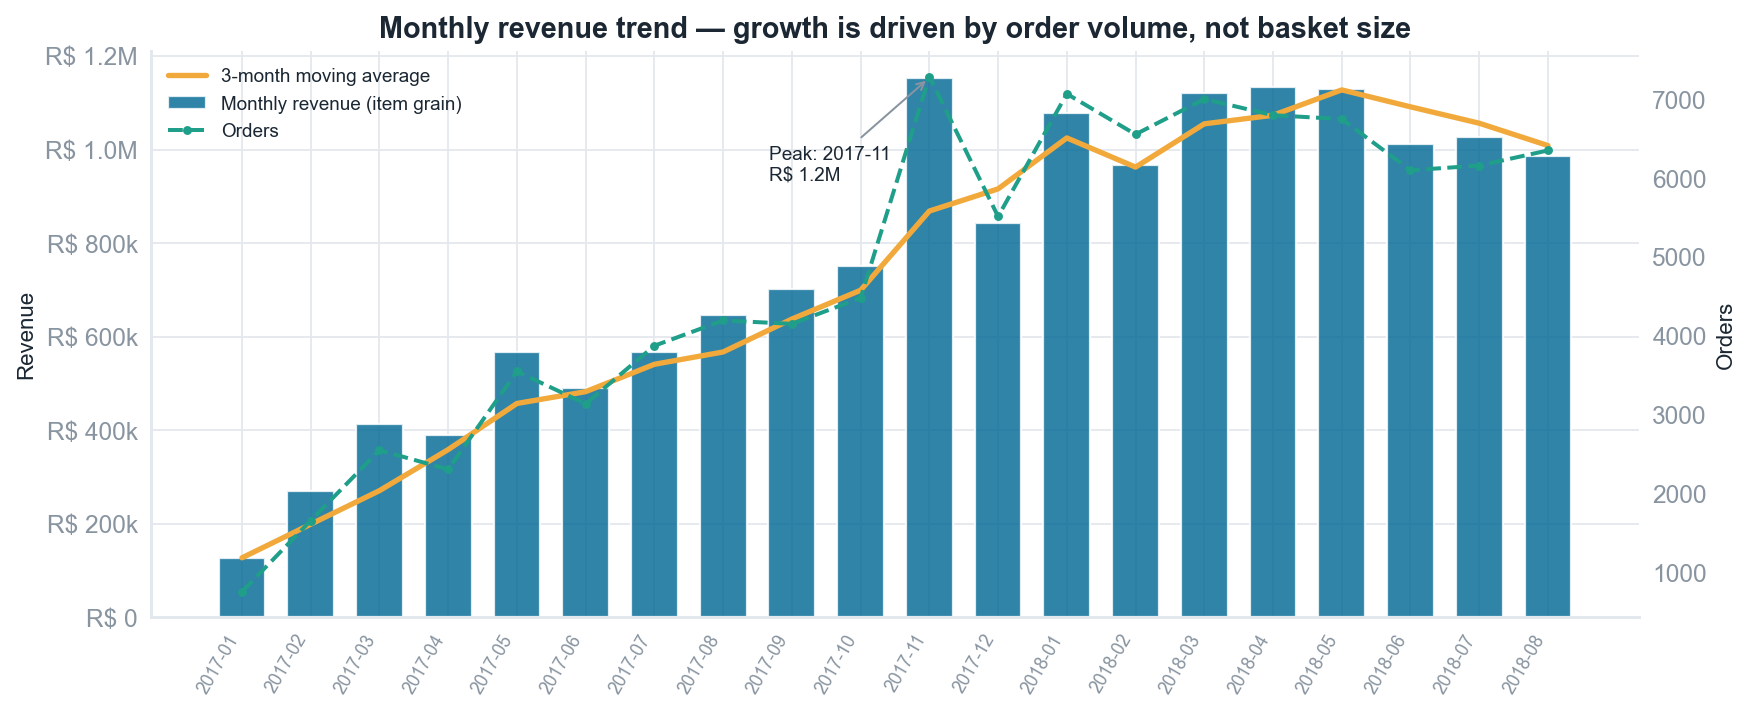

,purchase_month_key,orders,revenue,customers,aov,revenue_3m
14,2018-03,7003,"1,120,598.24",6914,160.02,"1,054,884.70"
15,2018-04,6798,"1,132,878.93",6744,166.65,"1,073,215.19"
16,2018-05,6749,"1,128,774.52",6693,167.25,"1,127,417.23"
17,2018-06,6099,"1,011,978.29",6061,165.93,"1,091,210.58"
18,2018-07,6159,"1,027,807.28",6100,166.88,"1,056,186.70"
19,2018-08,6351,"985,491.64",6310,155.17,"1,008,425.74"


In [18]:
monthly = fig_monthly_trend(win)
show("01_monthly_revenue_trend")
monthly.tail(6)

### 4.2 Seasonality & when people buy

November is the strongest month (Black Friday) at ~R$38k revenue/day vs ~R$23k in September.
Purchases cluster **Monday–Friday, 10:00–16:00** — B2C shopping happens during working hours,
which shapes when campaigns and support should be staffed.

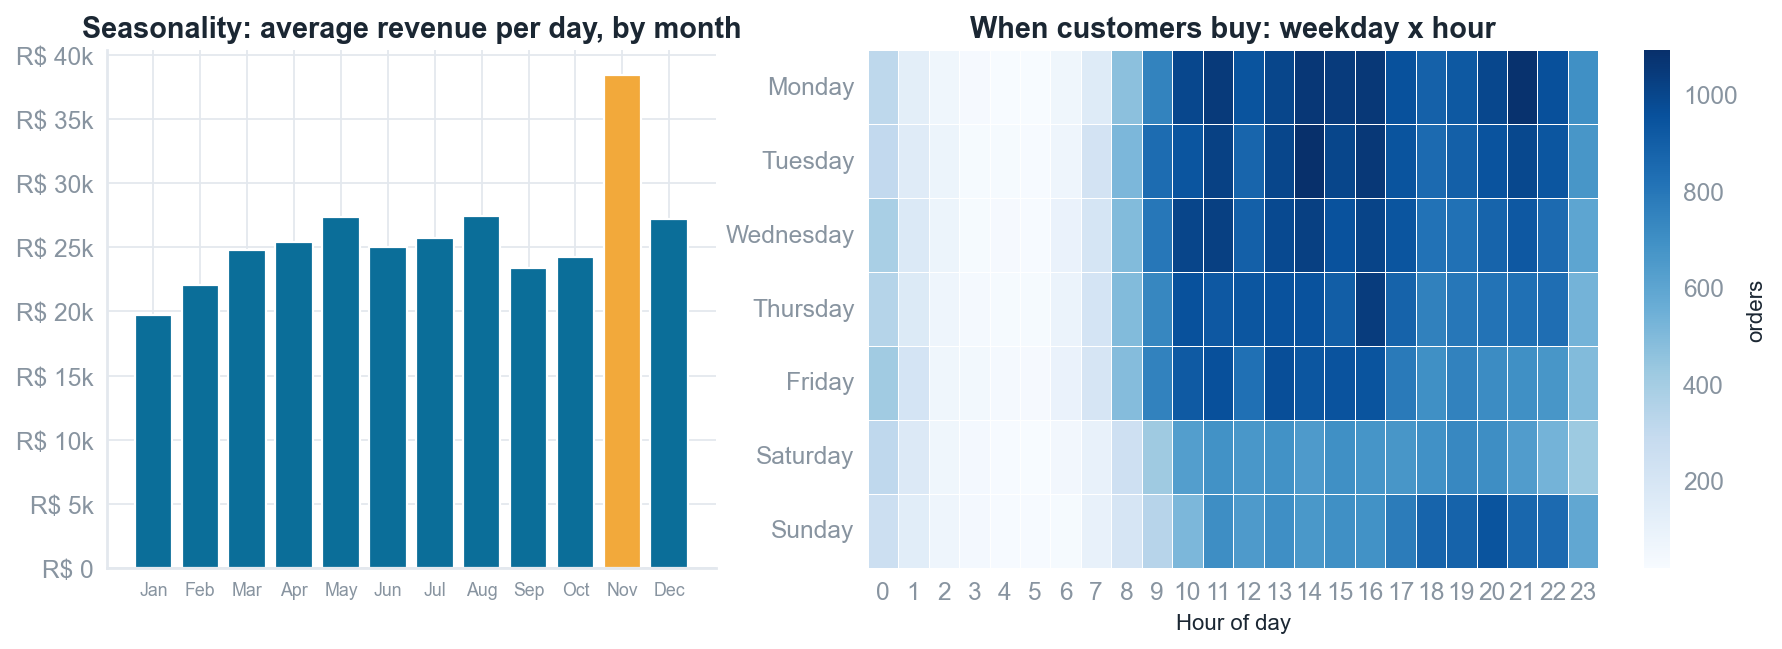

,month_name,avg_rev_per_day
0,1,"19,746.07"
1,2,"22,096.57"
2,3,"24,756.92"
3,4,"25,394.86"
4,5,"27,348.81"
5,6,"25,033.81"
6,7,"25,711.39"
7,8,"27,407.89"
8,9,"23,369.25"
9,10,"24,229.58"


In [19]:
season = fig_seasonality(win)
show("02_seasonality")
season

### 4.3 Payment methods

Credit card is 75% of orders and 78% of revenue; **boleto** (a Brazilian bank slip) is 20% of orders
but only 18% of revenue, and has a *lower* AOV (R$144 vs R$166) — boleto buyers are more price-sensitive
and are the natural target for a "pay in 3x" nudge.

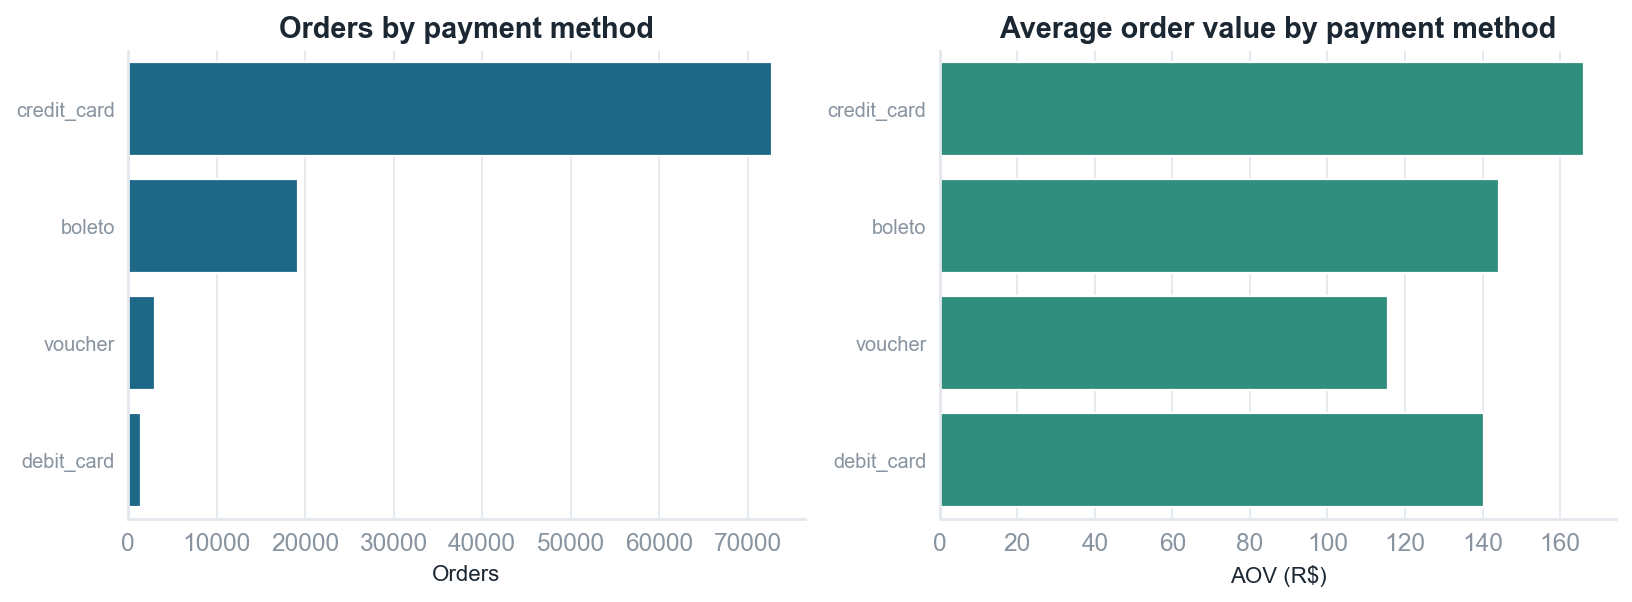

,payment_type,orders,revenue,aov,installments,order_share
1,credit_card,72785,"12,095,049.25",166.18,3.55,75.44
0,boleto,19191,"2,769,932.58",144.33,1.00,19.89
3,voucher,3017,"349,108.82",115.71,1.15,3.13
2,debit_card,1484,"208,371.12",140.41,1.00,1.54


In [20]:
pay = fig_payment_mix(fact)
show("03_payment_methods")
pay

### 4.4 Reviews vs delivery delay — the strongest relationship in the dataset

Being even **1–7 days late** cuts the average review from 4.28 to **2.84**, and 45.8% of those
customers give 1–2 stars. 8–15 days late → 1.73 stars. This is the business case for delivery ops.

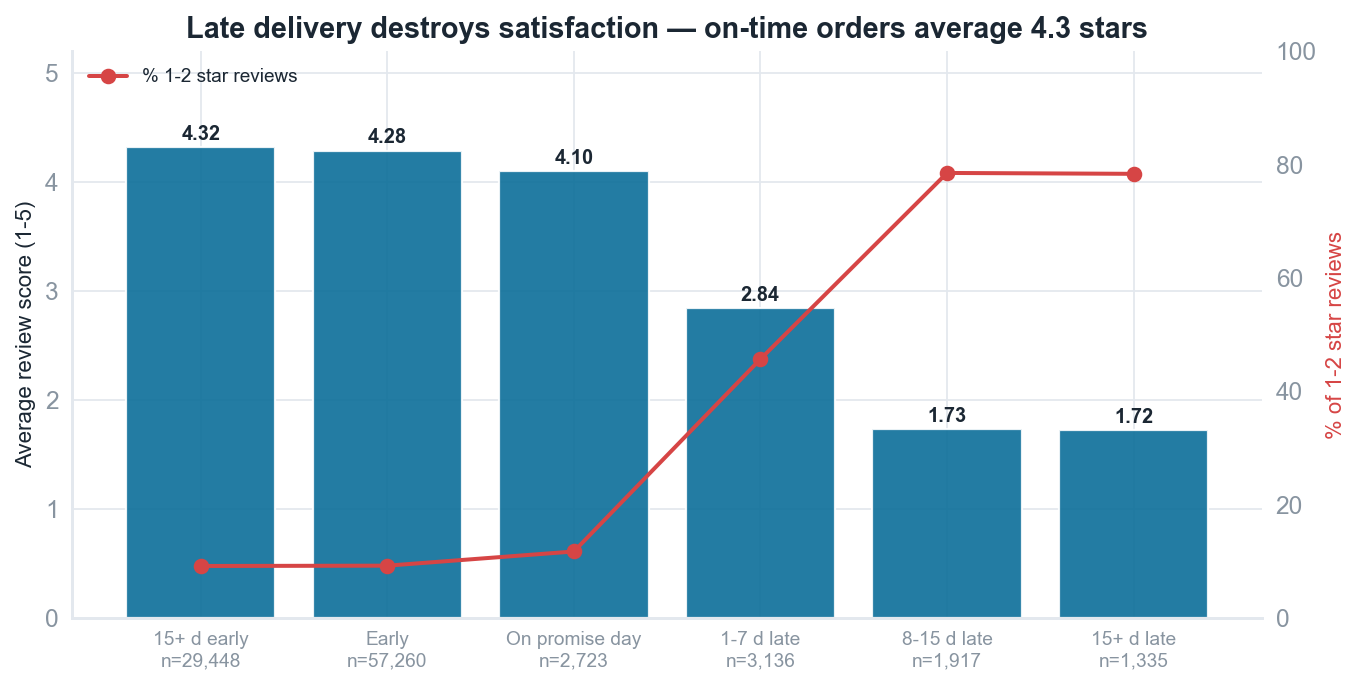

,delay_bucket,orders,avg_score,pct_low,avg_delivery
0,15+ d early,29448,4.32,9.16,9.89
1,Early,57260,4.28,9.21,11.23
2,On promise day,2723,4.10,11.72,18.00
3,1-7 d late,3136,2.84,45.66,24.98
4,8-15 d late,1917,1.73,78.51,33.82
5,15+ d late,1335,1.72,78.35,54.51


In [21]:
rev_delay = fig_review_vs_delay(fact)
show("04_review_vs_delay")
rev_delay

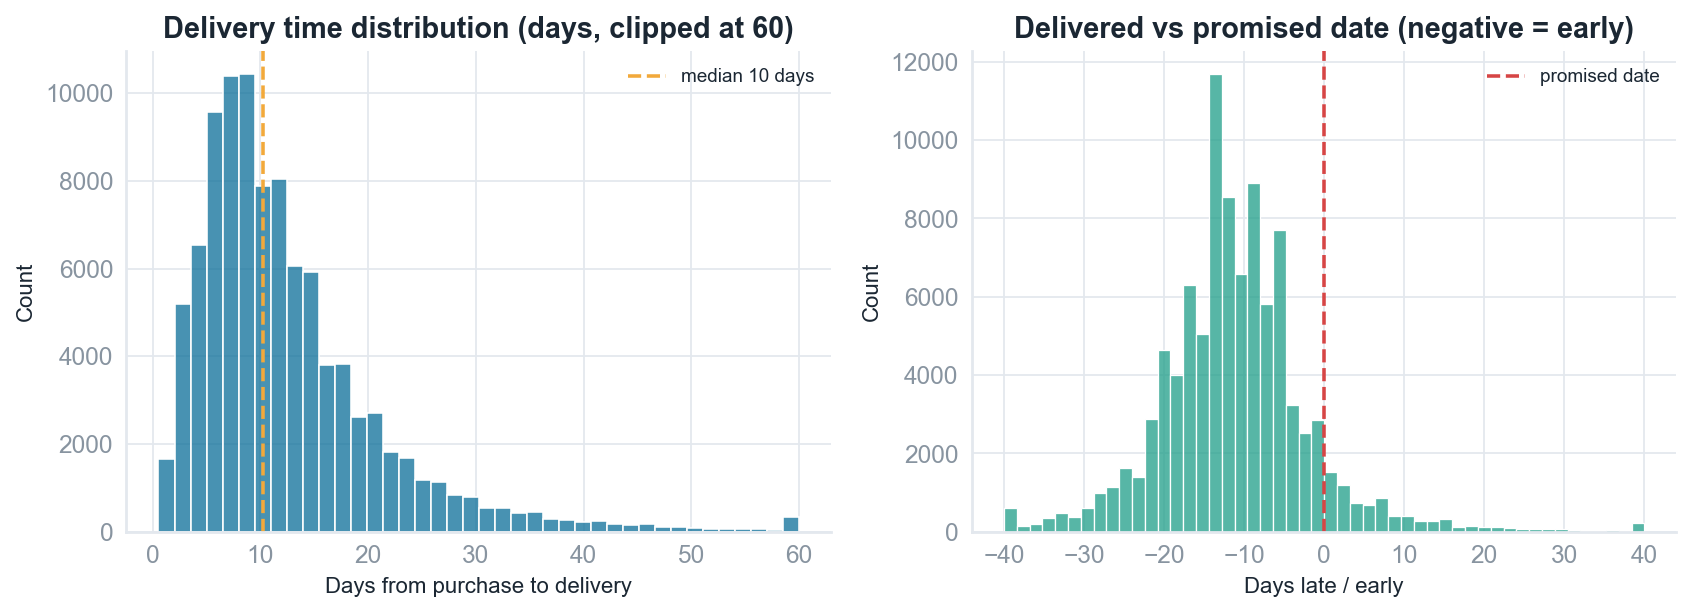

,index,delivery_days,delay_days,estimated_days
0,count,"96,470.00","96,470.00","96,470.00"
1,mean,12.56,-11.18,23.74
2,std,9.55,10.18,8.76
3,min,0.53,-146.02,2.01
4,25%,6.77,-16.24,18.33
5,50%,10.22,-11.95,23.23
6,75%,15.72,-6.39,28.41
7,max,209.63,188.98,155.14


In [22]:
desc = fig_delivery_distribution(fact)
show("05_delivery_distribution")
desc

### 4.5 Category-level average order value

The 15 biggest categories differ up to **2.9x** in AOV (Office Furniture R$267 vs Telephony R$93).
High AOV + mid revenue categories (Office Furniture, Cool Stuff) are the best candidates for
traffic investment; low AOV + high volume ones (Bed Bath Table, Health & Beauty) are basket-building targets.

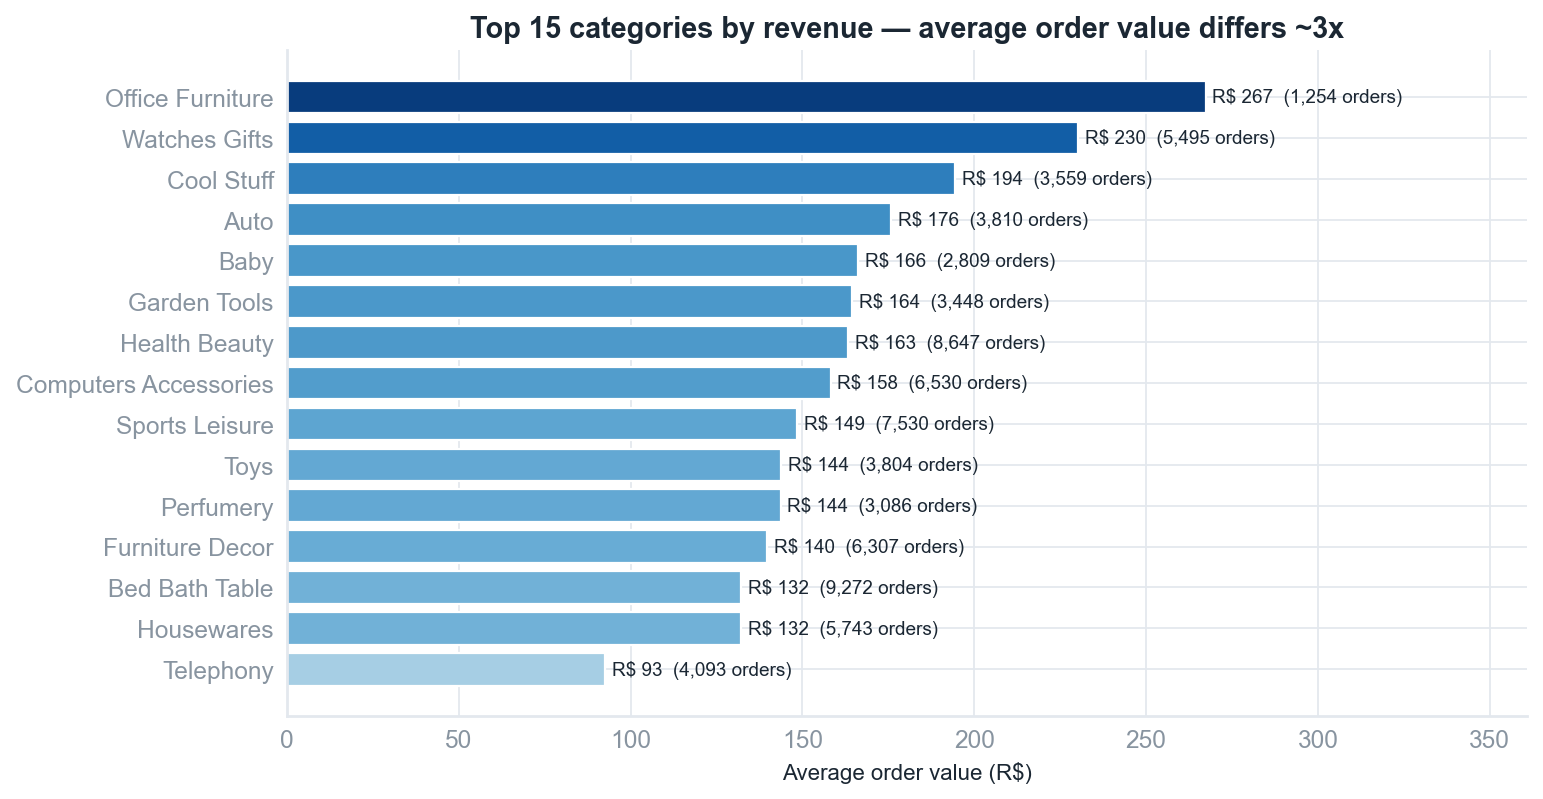

,category,revenue,orders,units,aov,rev_per_unit
43,Health Beauty,"1,412,089.53",8647,9465,163.30,149.19
73,Watches Gifts,"1,264,333.12",5495,5859,230.09,215.79
7,Bed Bath Table,"1,225,209.26",9272,10953,132.14,111.86
68,Sports Leisure,"1,118,256.91",7530,8431,148.51,132.64
15,Computers Accessories,"1,032,723.77",6530,7644,158.15,135.10
39,Furniture Decor,"880,329.92",6307,8160,139.58,107.88
49,Housewares,"758,392.25",5743,6795,132.06,111.61
20,Cool Stuff,"691,680.89",3559,3718,194.35,186.04
5,Auto,"669,454.75",3810,4140,175.71,161.70
42,Garden Tools,"567,145.68",3448,4268,164.49,132.88


In [23]:
cats = fig_category_aov(master)
show("06_category_aov")
cats.head(10)

### 4.6 Geography

SP alone is 37.4% of revenue. The right-hand panel (share of late deliveries) is the operational
map: the North-East (AL 23.9%, MA 19.7%, PI 16.0%) is where the promise is broken.

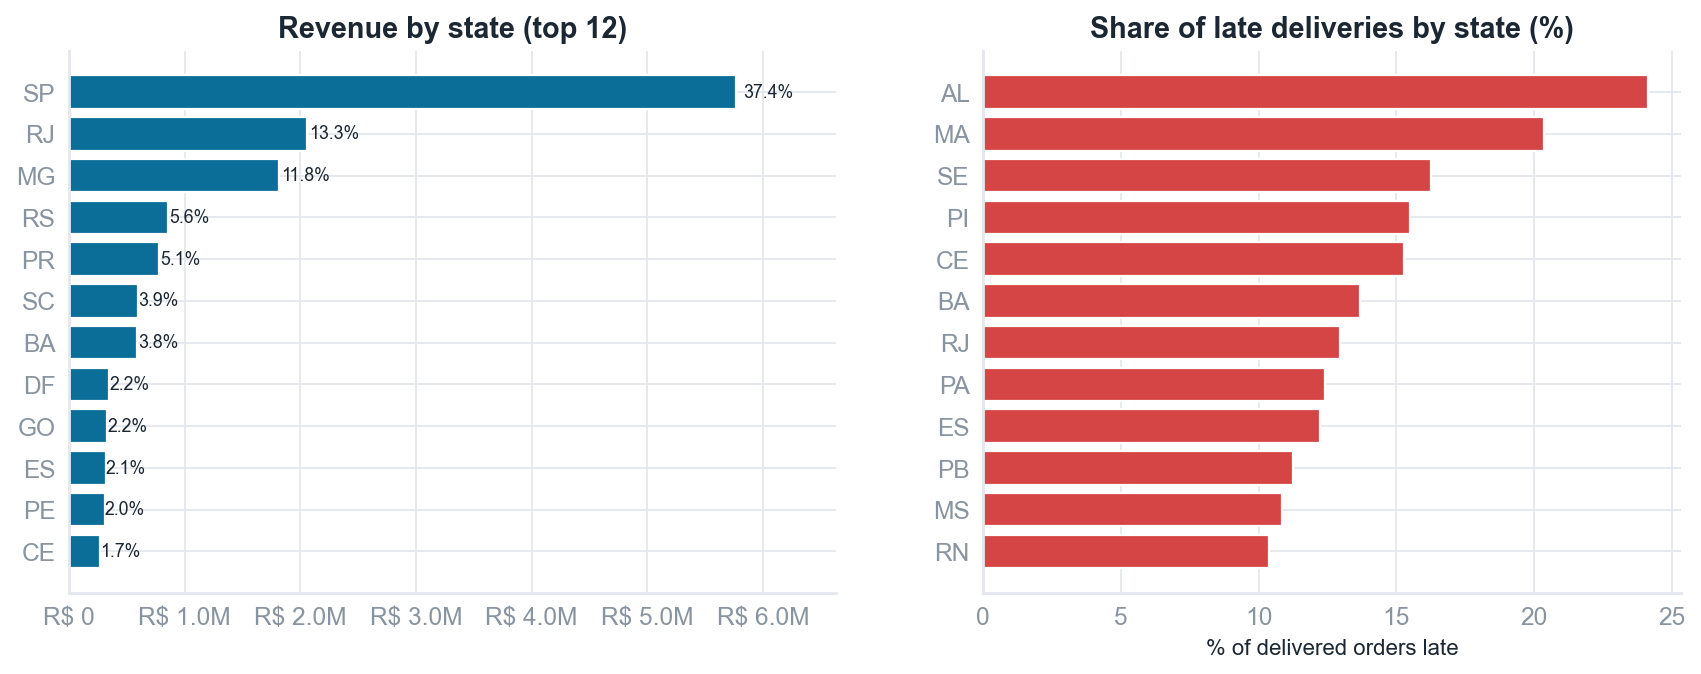

,customer_state,revenue,orders,customers,avg_delivery,pct_late,rev_share
25,SP,"5,769,703.15",40501,39156,8.72,0.06,37.42
18,RJ,"2,055,401.57",12350,11917,15.15,0.13,13.33
10,MG,"1,818,891.67",11354,11001,11.98,0.05,11.80
22,RS,"861,472.79",5345,5168,15.19,0.07,5.59
17,PR,"781,708.80",4923,4769,11.95,0.05,5.07
23,SC,"595,127.78",3546,3449,15.00,0.10,3.86
4,BA,"591,137.81",3256,3158,19.25,0.14,3.83
6,DF,"346,123.35",2080,2019,12.96,0.07,2.24
8,GO,"334,212.35",1957,1895,15.40,0.08,2.17
7,ES,"317,657.93",1995,1928,15.65,0.12,2.06


In [24]:
states = fig_geography(master)
show("07_geography")
states.head(10)

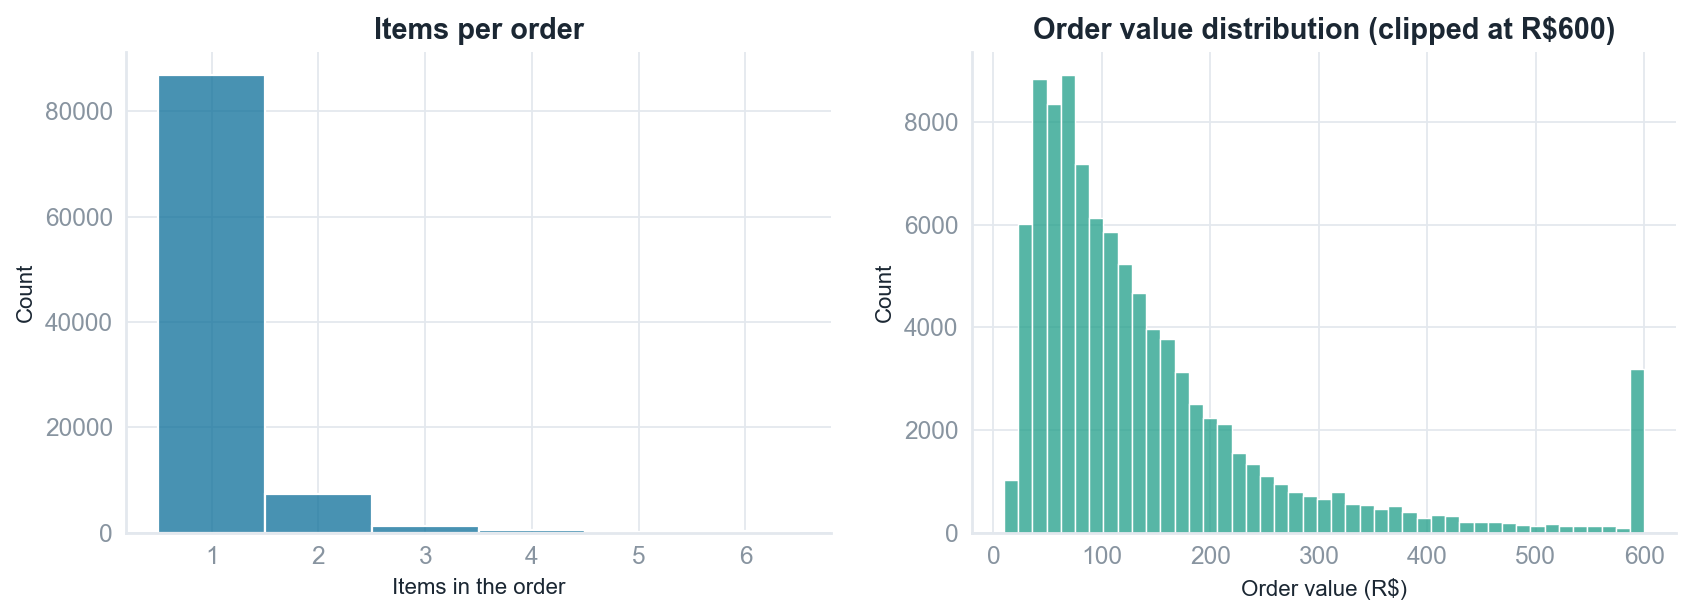

{'single_item_order_pct': 90.01,
 'median_order_value': 105.28,
 'order_value_p90': 305.97}

In [25]:
basket = fig_basket(master, fact)
show("12_basket_and_value")
basket

---
## 5. Step 5 — Advanced analysis

### 5.1 RFM segmentation

* **Recency** — days since the last order, scored in quintiles (5 = most recent)
* **Frequency** — number of distinct orders on `customer_unique_id`; explicit buckets 1 / 2 / 3+
  (quintiles would put 97% of customers in the same bucket and the score would carry no information)
* **Monetary** — total `payment_value`, quintiles (5 = highest)

Segments are assigned by a priority ladder (`segment_customers()`), so every customer lands in
exactly one bucket. The identical ladder is implemented in SQL (Q10) so both give the same answer.

In [26]:
from src.analysis import compute_rfm, rfm_summary, fig_rfm

rfm = compute_rfm(fact)
seg = rfm_summary(rfm)
print("snapshot date:", rfm.snapshot_date.iloc[0])
seg[["segment", "customers", "customer_share_pct", "revenue", "revenue_share_pct",
     "avg_frequency", "avg_recency", "avg_review"]].round(2)

snapshot date: 2018-08-30


,segment,customers,customer_share_pct,revenue,revenue_share_pct,avg_frequency,avg_recency,avg_review
0,New Customers,36140,38.71,"5,939,570.72",38.51,1.00,90.96,4.21
1,Hibernating,18111,19.40,"2,965,255.15",19.23,1.00,316.42,4.13
2,Lost,18236,19.53,"2,916,080.05",18.91,1.00,473.99,4.22
3,Promising,18070,19.36,"2,737,198.64",17.75,1.00,220.48,4.00
4,Champions,1129,1.21,"383,151.63",2.48,2.16,89.40,4.29
5,Cannot Lose Them,757,0.81,"271,072.46",1.76,2.09,379.88,4.18
6,Need Attention,602,0.64,"181,693.21",1.18,2.09,217.22,4.03
7,At Risk,239,0.26,"23,380.04",0.15,2.06,388.36,4.28
8,Loyal Customers,74,0.08,"5,059.87",0.03,2.00,86.46,4.31


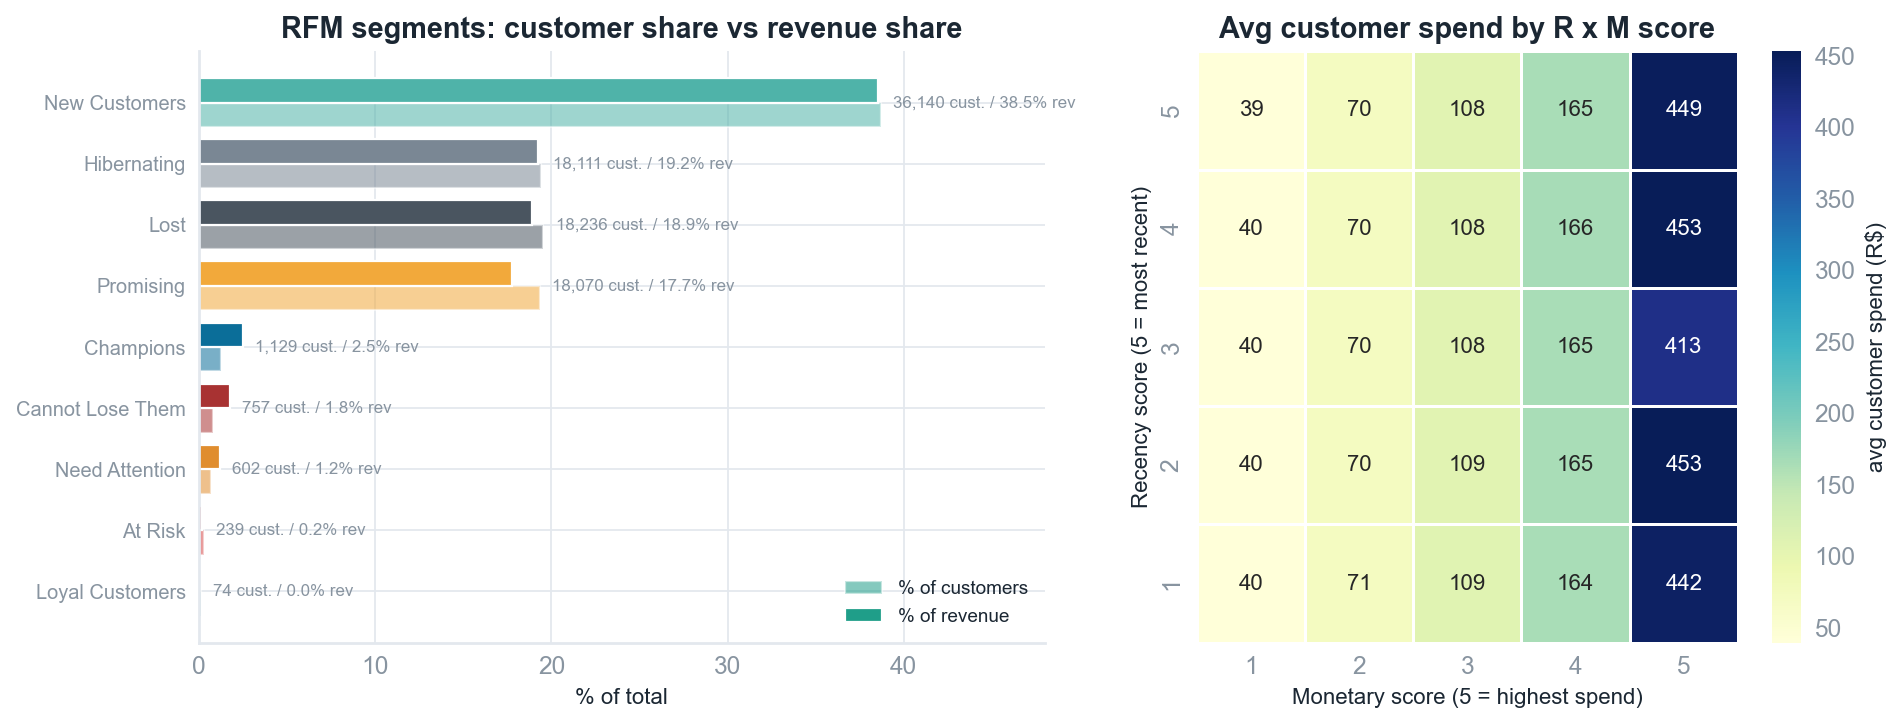

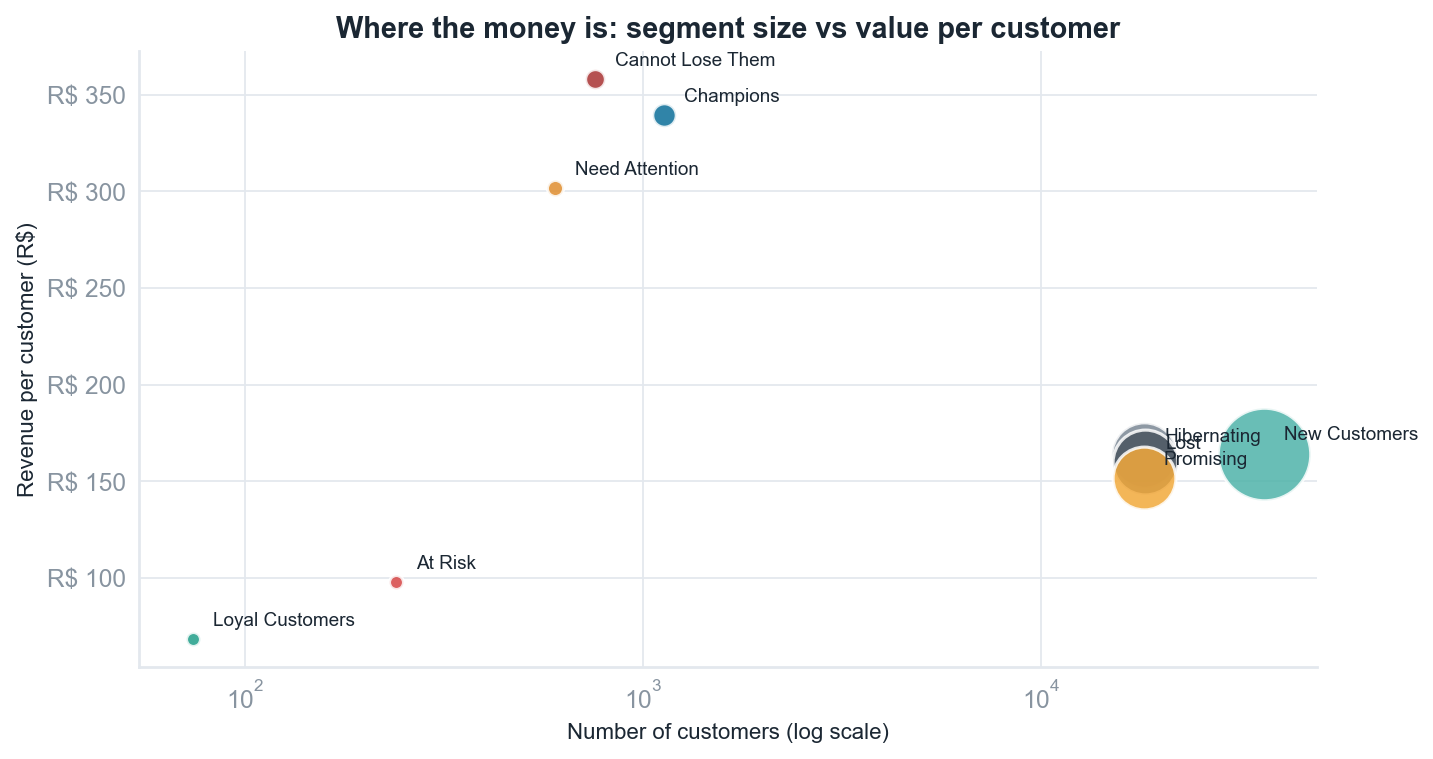

In [27]:
show("08_rfm_segments")
show("09_rfm_value_matrix")

**How to read this honestly.** The textbook promise — *"Champions are 15% of customers and 50% of revenue"* —
**does not hold for Olist**. Champions are 1.2% of customers and 2.5% of revenue. The reason is structural:
this is a one-purchase marketplace (97% single-order), so "loyalty" barely exists to be measured.

What *is* actionable:

| Segment | Customers | Share of revenue | Revenue / customer | Read |
|---|---|---|---|---|
| New Customers (recent, 1 order) | 36,140 | 38.5% | R$164 | the acquisition engine — convert within 90 days or lose them |
| Hibernating / Lost | 36,347 | 38.1% | R$162 | 19% of revenue from customers who have not returned in 4–12 months |
| Promising (mid-recency, 1 order) | 18,070 | 17.7% | R$151 | cheapest win-back audience |
| **Champions** (repeat + recent + high spend) | 1,129 | 2.5% | **R$339** | 2.1x the average customer — small but real |
| Cannot Lose Them (high spend, long gone) | 757 | 1.8% | **R$358** | highest value/customer in the base; win-back has a hard deadline |

So the valuable-customer answer is: **the top 5% of customers by spend (repeat or not) generate
**26.8%** of revenue, and the top 1% generate 10.3%**, and the highest-value individuals are *old* customers we have stopped serving.

In [28]:
# verify the "top 5% of customers by spend" claim
top5 = rfm.nlargest(int(len(rfm) * 0.05), "monetary")
print(f"top 5% of customers  -> {top5.monetary.sum()/rfm.monetary.sum()*100:.1f}% of revenue")
print(f"top 10% of customers -> {rfm.nlargest(int(len(rfm)*0.10),'monetary').monetary.sum()/rfm.monetary.sum()*100:.1f}% of revenue")

top 5% of customers  -> 26.8% of revenue
top 10% of customers -> 38.2% of revenue


### 5.2 Cohort retention

Cohort = month of the customer's **first** order. Retention = share of that cohort that ordered
again N months later. Month 0 is 100% by construction and is masked.

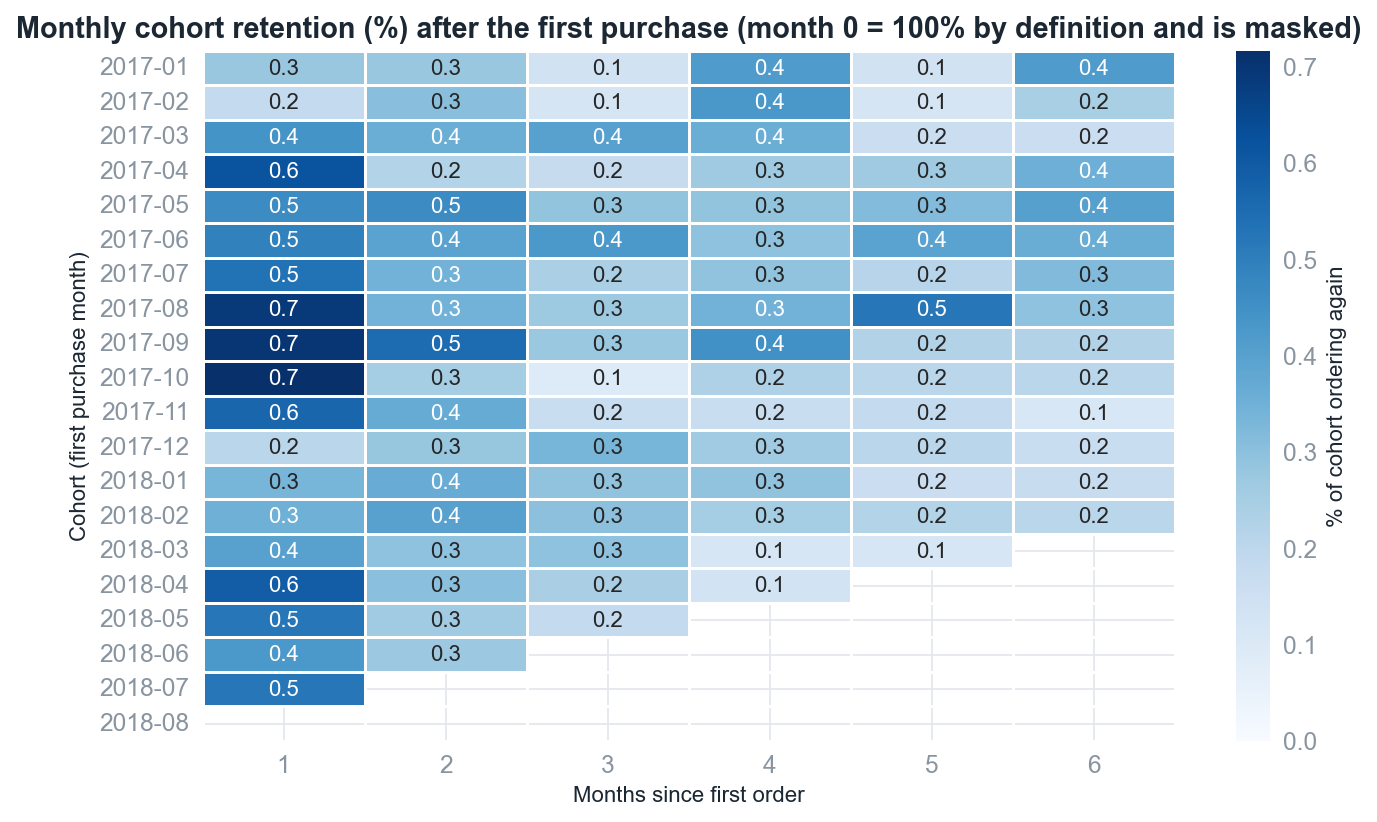

period,0,1,2,3,4,5,6
cohort_month,,,,,,,
2017-01,100.00,0.28,0.28,0.14,0.42,0.14,0.42
2017-02,100.00,0.18,0.31,0.12,0.43,0.12,0.25
2017-03,100.00,0.44,0.36,0.40,0.36,0.16,0.16
2017-04,100.00,0.62,0.22,0.18,0.27,0.27,0.35
2017-05,100.00,0.46,0.46,0.29,0.29,0.32,0.41
2017-06,100.00,0.49,0.40,0.43,0.30,0.40,0.36
2017-07,100.00,0.53,0.35,0.24,0.29,0.21,0.32
2017-08,100.00,0.69,0.35,0.27,0.35,0.52,0.30
2017-09,100.00,0.70,0.55,0.27,0.45,0.22,0.22


In [29]:
from src.analysis import cohort_analysis

cohort_counts, cohort_matrix = cohort_analysis(fact)
show("10_cohort_retention")
cohort_matrix.round(2)

Retention never exceeds **0.7% in any later month**, and it *decays* rather than recovering —
customers do not come back. This single chart explains why the business must be judged on
acquisition efficiency and first-order experience, not on loyalty-programme mechanics.

### 5.3 Pareto (80/20) on products

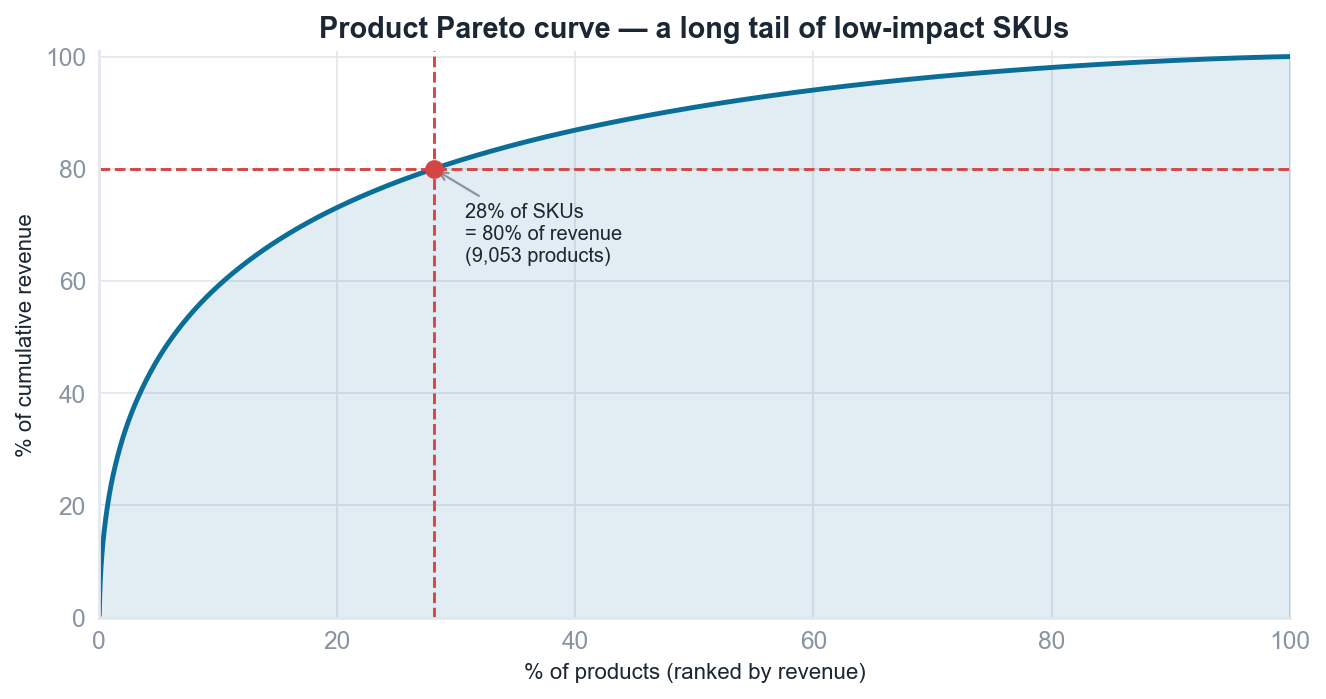

,value
n_products,"32,216.00"
n_products_for_80pct,"9,053.00"
pct_products_for_80pct,28.10
top20pct_products_revenue_share,73.12
top10pct_products_revenue_share,59.14


In [30]:
from src.analysis import pareto_products, fig_pareto

pareto_df, pareto_stats = pareto_products(master)
show("11_product_pareto")
pd.Series(pareto_stats).to_frame("value")

In [31]:
pareto_df.head(10)[["product_id", "category", "units", "revenue", "cum_pct_revenue"]]

,product_id,category,units,revenue,cum_pct_revenue
23546,bb50f2e236e5eea0100680137654686c,Health Beauty,194,"67,258.03",0.44
26436,d1c427060a0f73f6b889a5c7c61f2ac4,Computers Accessories,332,"58,957.31",0.82
13749,6cdd53843498f92890544667809f1595,Health Beauty,153,"57,933.73",1.19
19290,99a4788cb24856965c36a24e339b6058,Bed Bath Table,477,"49,907.50",1.52
7881,3dd2a17168ec895c781a9191c1e95ad7,Computers Accessories,272,"47,876.06",1.83
26997,d6160fb7873f184099d9bc95e30376af,Computers,33,"47,314.18",2.14
21617,aca2eb7d00ea1a7b8ebd4e68314663af,Furniture Decor,520,"44,197.75",2.42
12074,5f504b3a1c75b73d6151be81eb05bdc9,Cool Stuff,63,"41,725.81",2.69
4892,25c38557cf793876c5abdd5931f922db,Baby,38,"40,311.95",2.95
10616,53b36df67ebb7c41585e8d54d6772e08,Watches Gifts,321,"39,713.49",3.21


---
## 6. Step 6 — Dashboard

`dashboard/olist_dashboard.html` is a **self-contained interactive dashboard** (no server, no internet
needed) with the four pages from the brief and live filters (month range, state, category):

1. **Sales overview** — KPIs, monthly trend, payment mix, review-vs-delay, order-value distribution
2. **Products & categories** — category revenue & AOV, Pareto curve, category table
3. **Customer segments** — RFM bars, repeat-purchase reality, cohort heatmap, segment table
4. **Geography & delivery** — revenue by state, promise vs reality, late-delivery rates, state table

A Power BI build pack (`powerbi/`) ships the star-schema CSVs and DAX measures so the same four
pages can be rebuilt in Power BI Desktop.

Run it with: `python -m dashboard.build_dashboard` then open the HTML file.

**Page: overview**

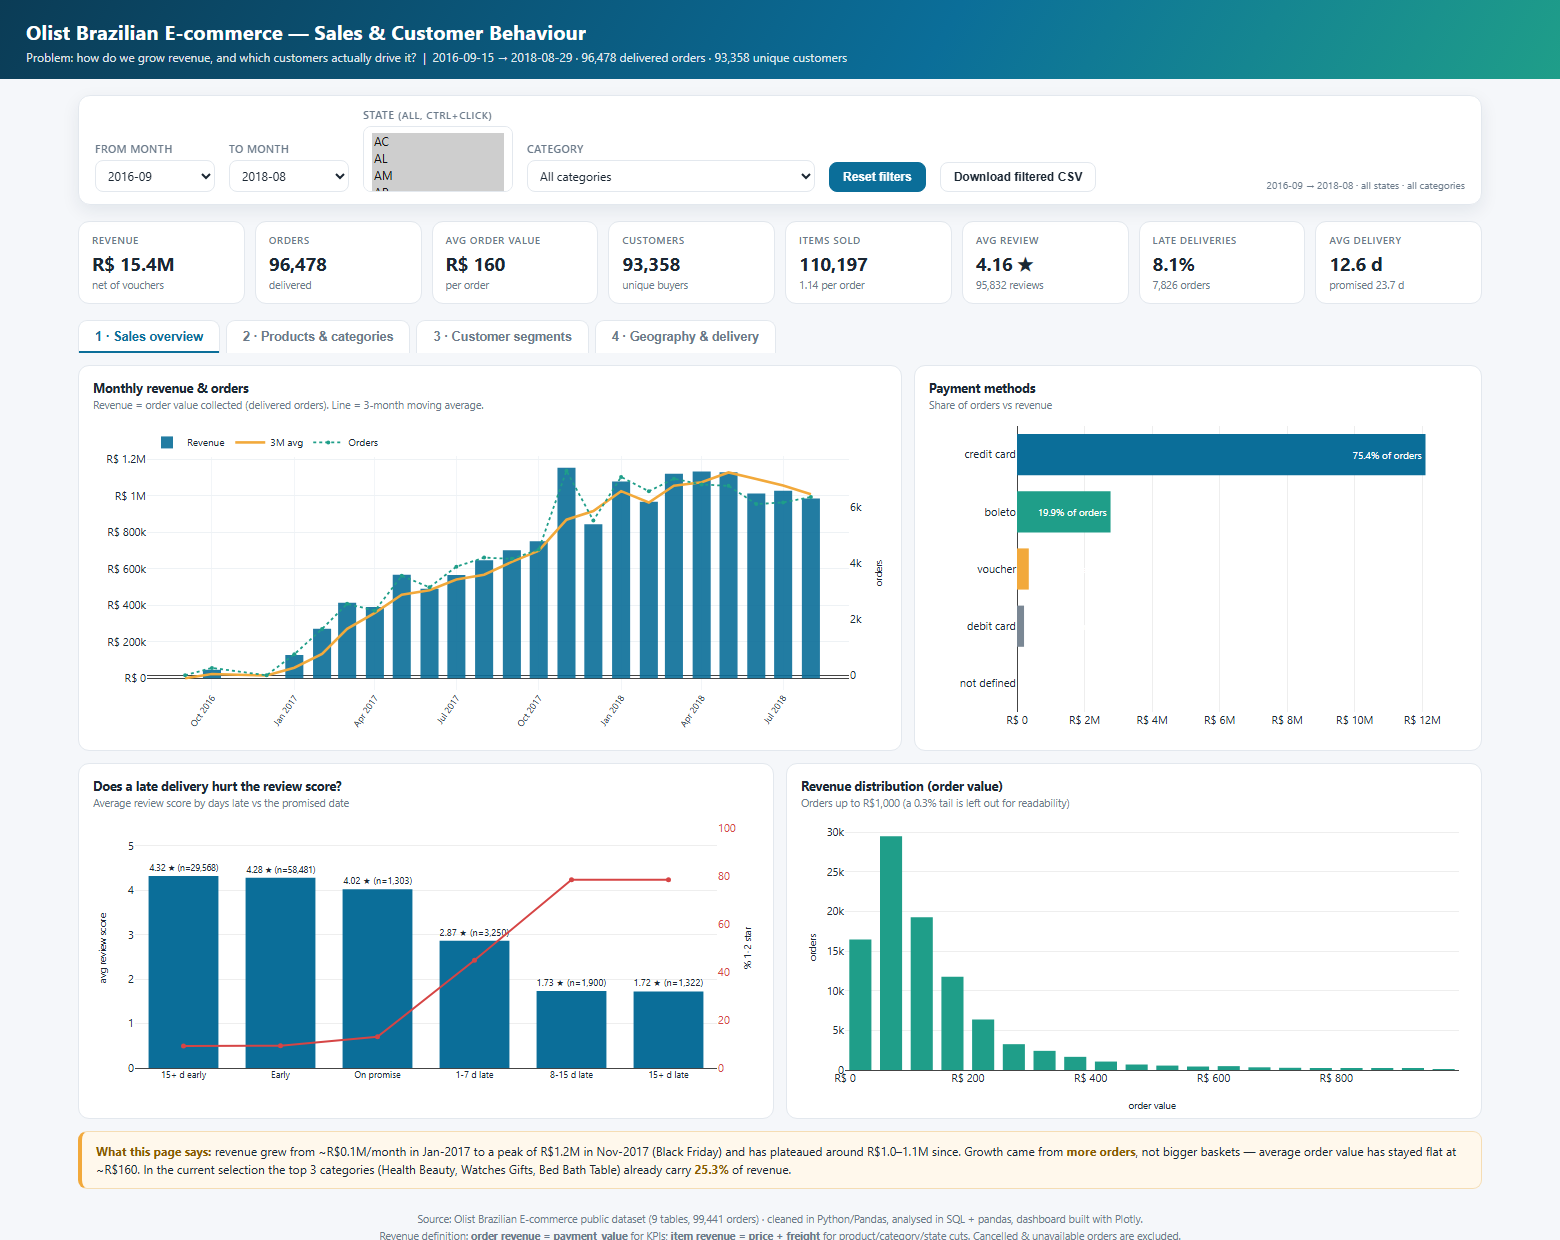

**Page: products**

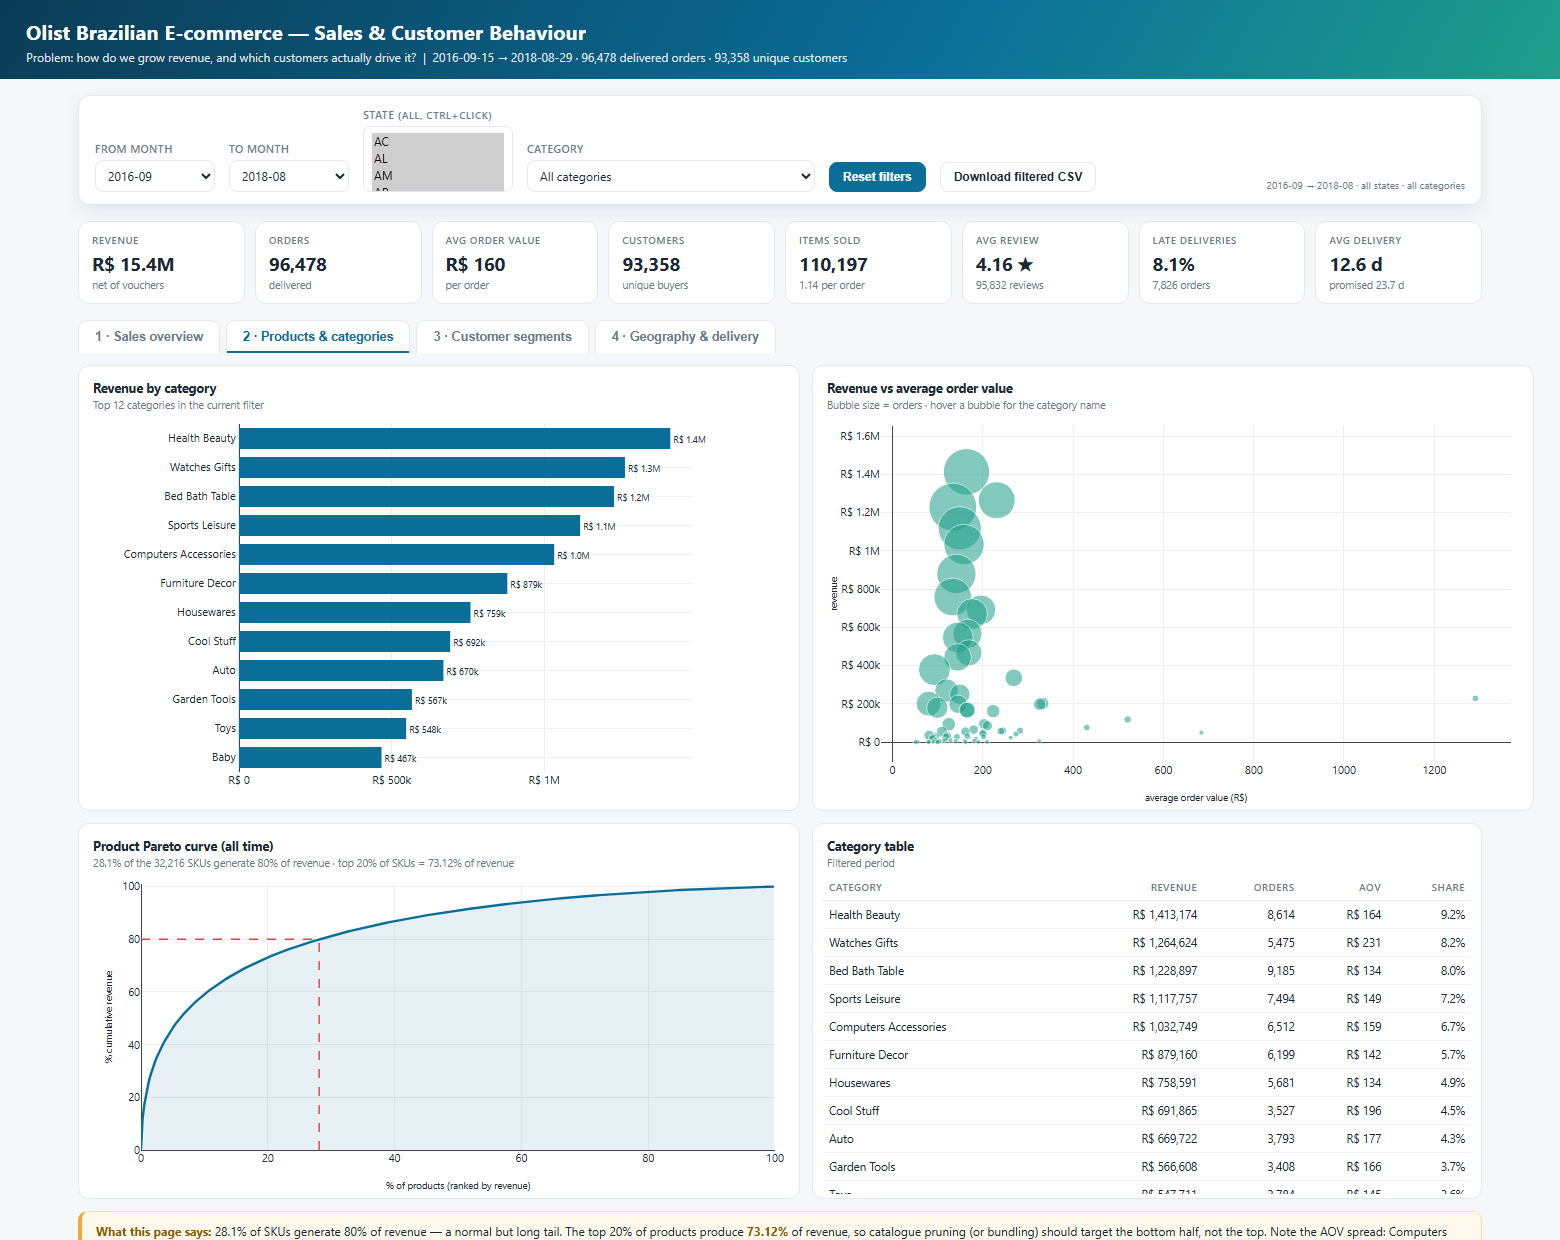

**Page: customers**

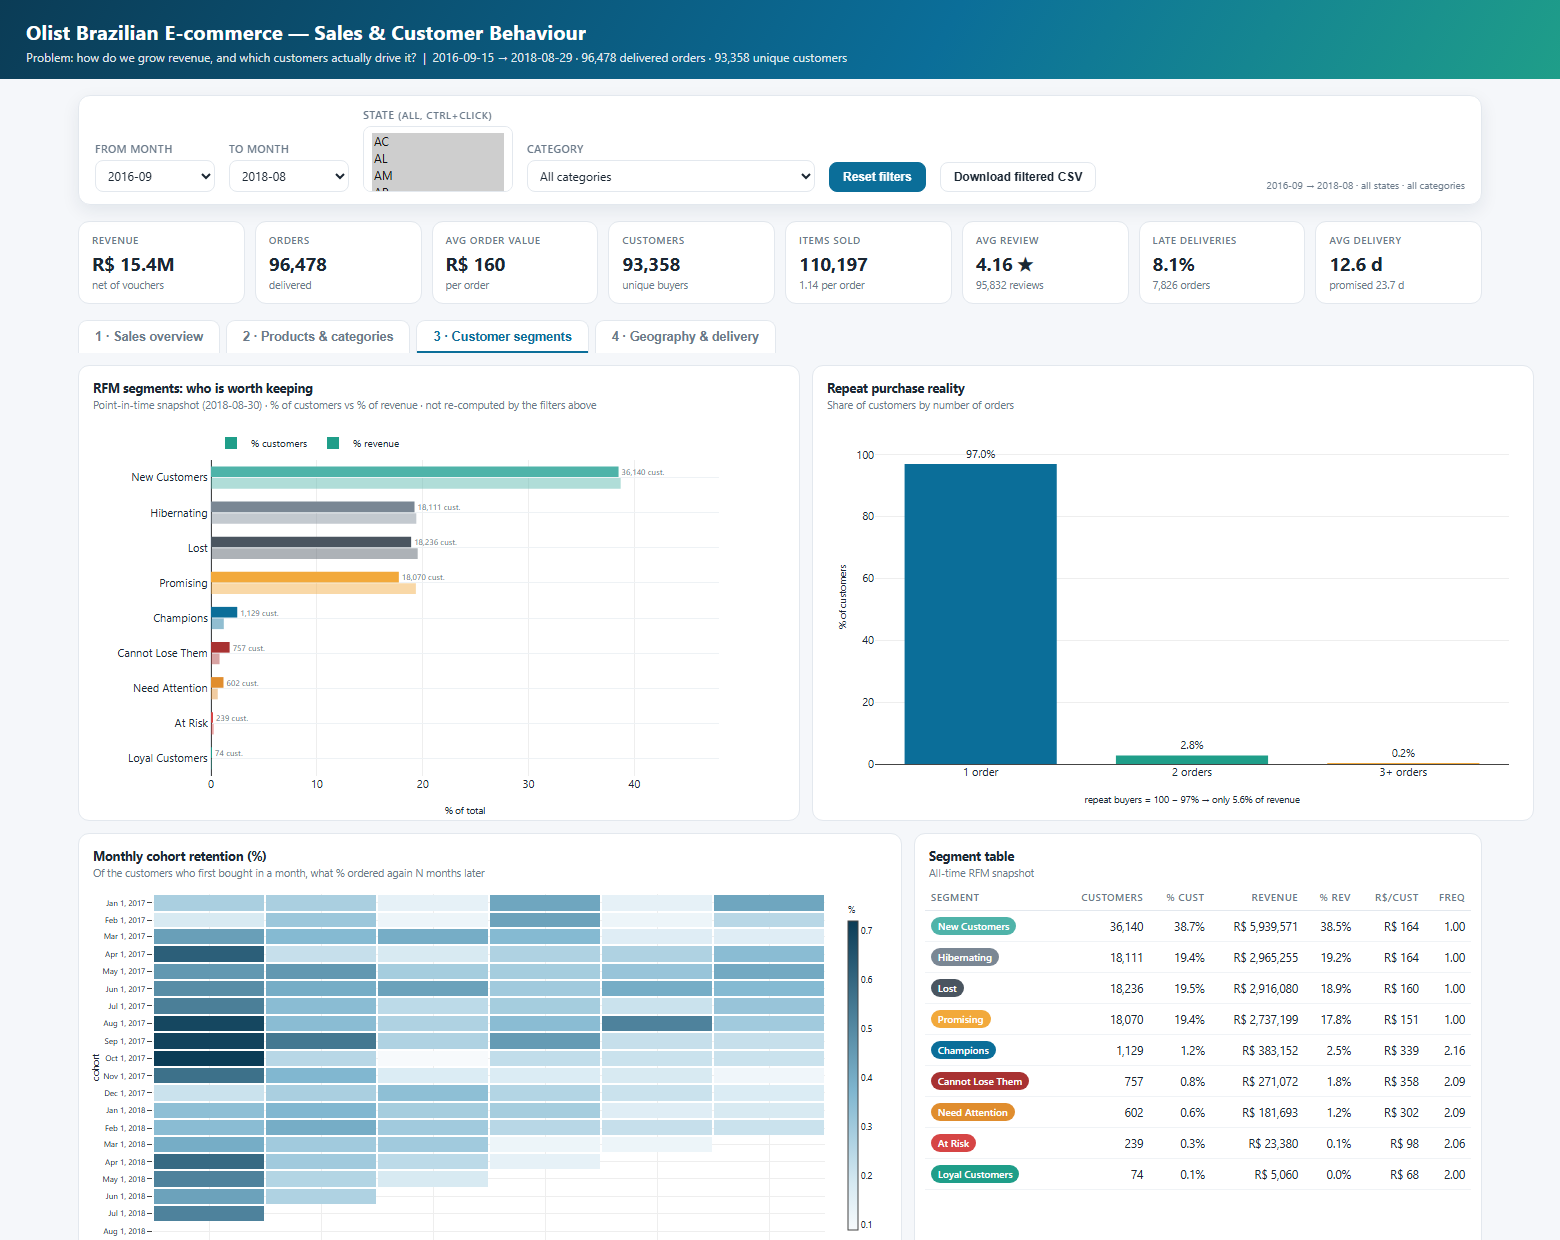

**Page: geo**

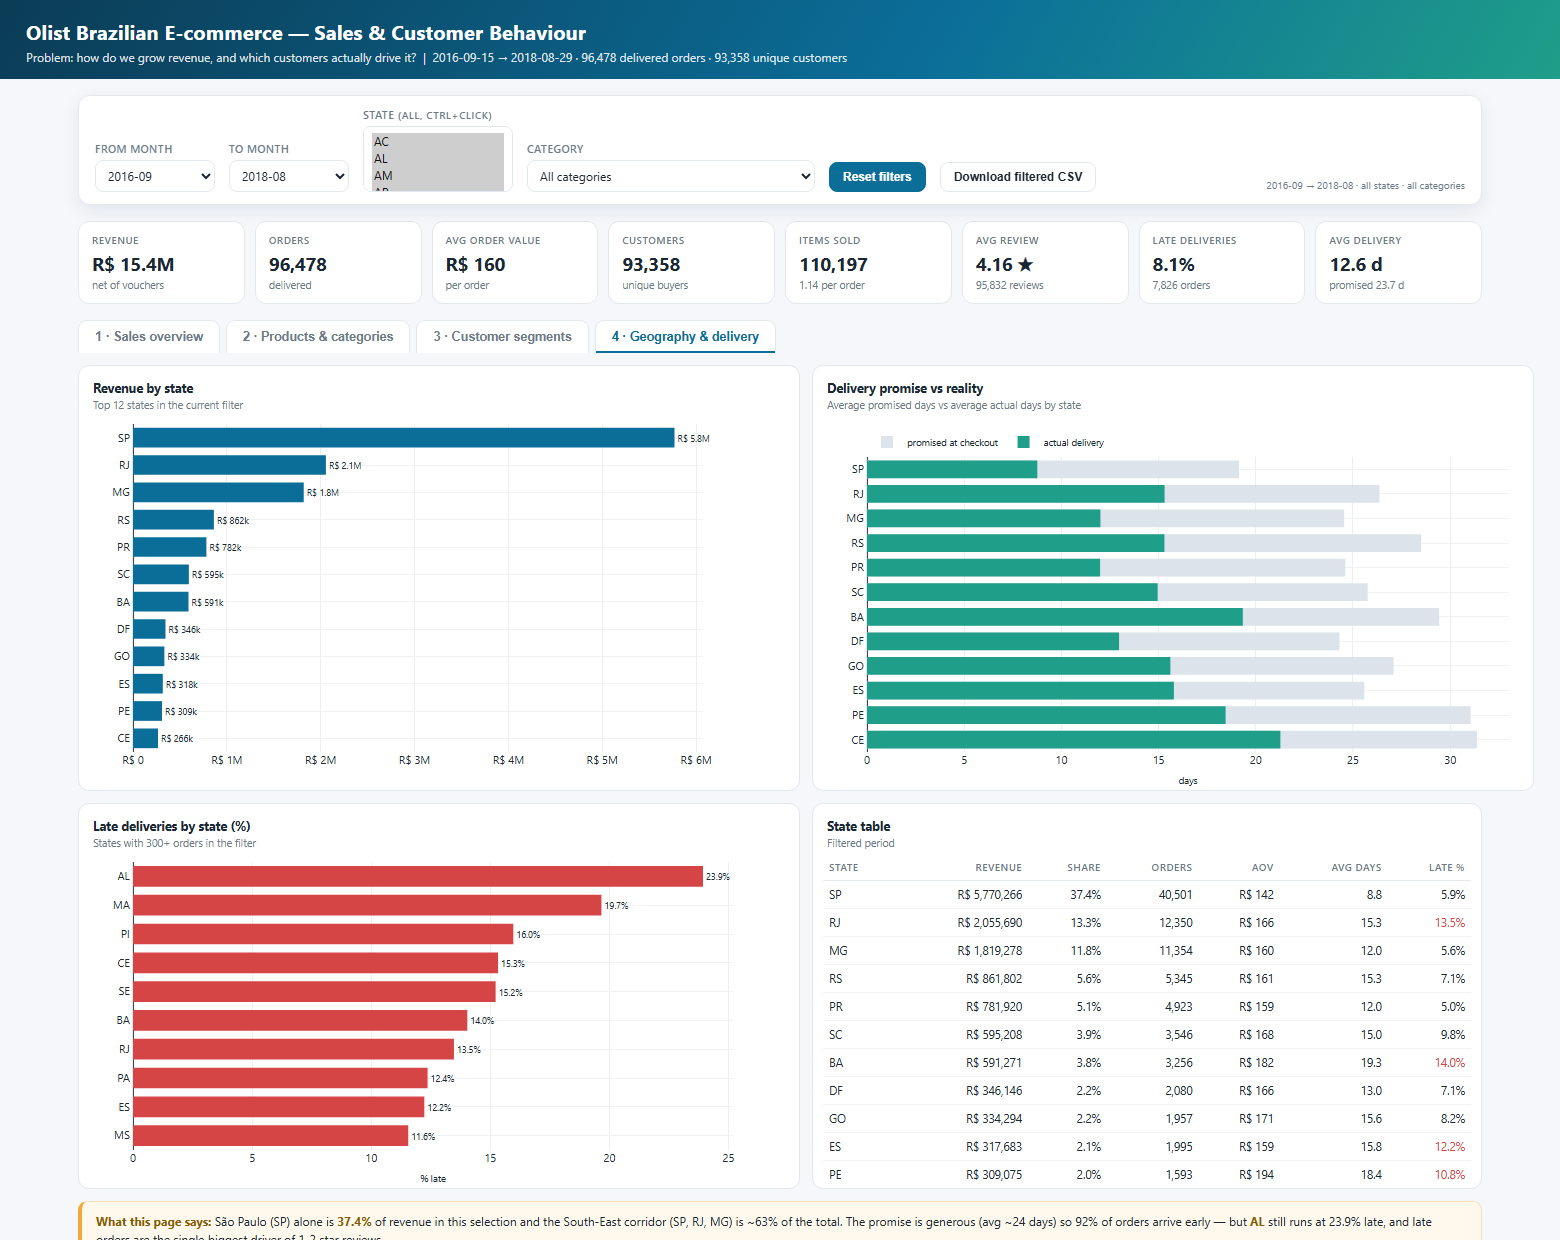

In [32]:
from IPython.display import Image, display
for page in ["overview", "products", "customers", "geo"]:
    display(Markdown(f"**Page: {page}**"))
    display(Image(filename=str(ROOT / "dashboard" / "screenshots" / f"page_{page}.png"), width=900))

---
## 7. Step 7 — Insights & recommendations

**1. Growth is volume-driven, and the flat AOV is the open opportunity.**
Revenue went R$0.13M → R$1.16M/month (Jan-2017 → Nov-2017) purely on order count; AOV sat at
R$146–170 for 20 months. A 10% AOV lift on the current base is ~R$1.5M/year with **no extra
acquisition spend** — bundling in Bed Bath Table / Housewares (AOV R$132–134, 9,000+ orders each)
is the cheapest lever.

**2. The Nov-2017 Black Friday peak (+53.6% MoM, R$0.75M → R$1.15M) was not repeated — December fell back 26.9%.**
Plan the campaign calendar around Nov (peak), and use Sep (weakest, R$23k/day) for retention pushes.

**3. Delivery is the profit-and-reputation lever, not a logistics footnote.**
Late orders average **1.7–2.8 stars** vs 4.3 on time; 12.8% of all reviews are 1–2 star.
Cutting the late rate from 8.1% to 4% would have avoided ~4,900 of the 7,826 late orders in this history.
Focus on AL (23.9% late), MA (19.7%), PI (16.0%), CE (15.3%).

**4. Stop over-promising in the North-East.**
Average promised time is 30–45 days there vs 12.6 days actual delivery — the promise is so padded
that customers are surprised. A tighter, honest promise (e.g. 20 days) plus a real SLA would convert
the same operational performance into better perceived service.

**5. The customer base is transactional: 97% buy once, repeat buyers are 5.6% of revenue.**
A classic loyalty programme is the wrong investment. The right one is **first-90-day activation**:
a second-purchase incentive timed 15–30 days after delivery (cohort retention at month 1 is ~0.4%),
targeted at the 36,140 New Customers (38.5% of revenue).

**6. The most valuable customers are Champions + "Cannot Lose Them" — 1,886 people (2.0%) worth R$339–358 each.**
They are 2.1x the average customer and 4.2% of revenue. Treat them as a VIP list: priority support,
early access to the Nov campaign, and a personal win-back for the 757 high-spend customers who
have not ordered in 12+ months.

**7. Payment mix is a conversion lever.**
Credit card = 75% of orders with 3.6 installments average; boleto = 20% of orders with a 13% lower AOV.
Offering interest-free installments on boleto-converted carts (or a small boleto discount) attacks
checkout abandonment in the segment that is most price-sensitive.

**8. Catalogue: 28% of SKUs (9,053 products) make 80% of revenue.**
The bottom half of the catalogue carries almost no revenue but full inventory/support cost.
Freeze new SKUs in the tail, and reallocate merchandising to the top categories
(Health & Beauty, Watches & Gifts, Bed Bath Table = 25% of revenue).

### What I would do next (30/60/90)
* **30 days** — instrument first-90-day repeat rate; launch a second-purchase voucher at day 21 post-delivery.
* **60 days** — tighten delivery promises in the North-East, publish an SLA for AL/MA/PI; add a "late order" recovery email.
* **90 days** — bundle test in Bed Bath Table/Housewares; VIP programme for the 1,886 high-value customers.

---
## 8. Limitations

1. **No cost or margin data** — revenue is gross merchandise value plus freight; profitability cannot be measured.
2. **No marketing spend / channel data** — CAC, ROAS and channel-level ROI are out of scope.
3. **No returns table** — refunds are inferred only from `unavailable`/`canceled` statuses.
4. **Censored horizon** — 2016-09→12 and 2018-09 are partial months; all trends are plotted on 2017-01→2018-08.
5. **RFM is a snapshot** (2018-08-30) — recency scores age with the data, and cohort months after 2018-02 have
   fewer observable periods (right-censoring).
6. **Primary-category attribution** — orders spanning multiple categories are assigned to their highest-value
   category in the dashboard, which slightly under-counts secondary categories.